# Proyecto Final de Bioinformática 2026

## Respuesta transcripcional al Huanglongbing en portainjertos de cítricos tolerante y susceptible

**Materia:** Bioinformática (4° año, Bioingeniería)
**Docente:** Lic. Esp. Ignacio Garcia Labari
**Fecha:** Noviembre de 2026

---

## La pregunta que quiero responder

> **¿Qué diferencia la respuesta a la infección por *Candidatus* Liberibacter asiaticus entre un
> portainjerto de cítrico tolerante (US-897) y uno susceptible (mandarina 'Cleopatra')?**

No existen cultivares de cítricos resistentes al HLB, pero sí hay genotipos **tolerantes**: plantas
que se infectan igual pero no desarrollan síntomas severos ni colapsan. Entender en qué se
diferencia la respuesta de una planta tolerante de la de una susceptible es lo que podría orientar
el mejoramiento hacia portainjertos que aguanten la enfermedad, que hoy es la única vía de manejo
que no depende de erradicar.

Todo lo que sigue en este notebook está puesto para responder esa pregunta. Cada sección termina con
una conclusión parcial que dice qué aporta a la respuesta, y la conclusión final la contesta de
forma directa.

### Por qué elegí este tema

El Huanglongbing (HLB), también llamado "greening" o "enverdecimiento de los cítricos", es hoy la
enfermedad más destructiva de la citricultura a nivel mundial. No tiene cura: una vez que una planta
se infecta, el manejo consiste en erradicarla para que no sirva de fuente de inóculo.

Elegí el tema porque en Tucumán la citricultura es una de las principales actividades productivas y
el HLB es una amenaza concreta y vigente. Existe un comité de vigilancia que integran SENASA, la
EEAOC, el INTA Famaillá, el Ministerio de Producción de la provincia y AFINOA, donde trabaja mi papá
como ingeniero agrónomo. Esa cercanía fue lo que me hizo querer entender el problema desde el lado
de los datos.

### Cómo se descompone la pregunta

Para contestarla hacen falta dos cosas, y de ahí salen los dos bloques del trabajo.

Primero hay que saber **con qué patógeno estamos tratando** y qué podemos averiguar sobre él. Eso es
el bloque 1: reconstruyo la filogenia del género *Candidatus* Liberibacter con secuencias del gen
16S rDNA, incluidas las argentinas publicadas, para identificar qué especie circula acá y determinar
hasta qué nivel taxonómico ese marcador alcanza. El resultado de ese bloque es el que define sobre
qué tipo de datos se puede responder la pregunta central, y se explica al final de la sección 6.

Después hay que **medir la respuesta del hospedante**. Eso es el bloque 2: analizo una matriz de
expresión génica de un ensayo donde se compararon los dos portainjertos, infectados y sanos, con las
técnicas de minería de datos y machine learning de la materia.

### Objetivos

El objetivo general es responder la pregunta de arriba. Los objetivos específicos son los pasos para
llegar:

1. Identificar la especie de *Candidatus* Liberibacter presente en Argentina y establecer el alcance
   del gen 16S rDNA como marcador, para saber qué tipo de datos permite responder la pregunta
   central y cuál no.
2. Explorar si la estructura de la matriz de expresión es consistente con los dos factores del
   diseño experimental, genotipo y tratamiento, mediante reducción de dimensionalidad y clustering
   no supervisado.
3. **Cuantificar la respuesta a la infección por separado en cada genotipo y compararlas.** Este es
   el objetivo que responde directamente la pregunta central.
4. Determinar si las diferencias entre los dos genotipos son constitutivas, es decir previas a la
   infección, o inducidas por ella.
5. Identificar los genes que mejor discriminan el estado de infección y evaluar con honestidad qué
   se puede y qué no se puede concluir con 12 muestras.

---

## 1. Los experimentos de donde vienen los datos

Trabajo con dos conjuntos de datos distintos, cada uno con su paper cabecera.

### 1.1 Datos de secuencias: el relevamiento argentino de HLB

**Paper cabecera:**

> Badaracco, A., Redes, F.J., Preussler, C.A. y Agostini, J.P. (2017). *Citrus huanglongbing in
> Argentina: detection and phylogenetic studies of 'Candidatus Liberibacter asiaticus'*.
> Australasian Plant Pathology, 46(2), 171-175.

Los autores pertenecen a la Estación Experimental Agropecuaria Montecarlo del INTA (Centro Regional
Misiones) y al CONICET. El trabajo está disponible en acceso abierto en CONICET Digital
(http://ri.conicet.gov.ar/handle/11336/72858).

**Qué hicieron:** entre 2012 y 2016 relevaron la presencia y la diversidad genética de *Ca.* L.
asiaticus en Argentina. Analizaron 1187 muestras de hojas de cítricos por nested-PCR con cebadores
específicos, amplificando un fragmento de 1160 pb del 16S rDNA. Dieron positivas 76 muestras, un
6,4% del total. De ese conjunto seleccionaron 7 muestras representativas, las secuenciaron y
depositaron las secuencias en GenBank. Con esas secuencias más referencias internacionales
construyeron un árbol filogenético por Neighbor-Joining usando el modelo de dos parámetros de Kimura
en MEGA6.

**Qué encontraron:** las secuencias argentinas no formaron un grupo monofilético, sino que quedaron
distribuidas junto a secuencias de distintas partes del mundo.

### 1.2 Datos de expresión: respuesta transcripcional de cítricos tolerante y susceptible

**Paper cabecera:**

> Albrecht, U. y Bowman, K.D. (2012). *Transcriptional response of susceptible and tolerant citrus to
> infection with 'Candidatus Liberibacter asiaticus'*. Plant Science, 185-186, 118-130.

Los autores trabajan en el U.S. Horticultural Research Laboratory del USDA-ARS en Fort Pierce,
Florida, y en el Southwest Florida Research and Education Center de la Universidad de Florida.

**Qué hicieron:** el punto de partida es que no se conocen cultivares de cítricos resistentes al HLB,
pero sí hay genotipos tolerantes, es decir que se infectan pero no desarrollan síntomas severos.
Uno de ellos es US-897, un híbrido de *Poncirus trifoliata* con mandarina 'Cleopatra'. Compararon
plántulas de US-897 (tolerante) y de mandarina 'Cleopatra' (susceptible), injertadas con tejido
infectado con *Ca.* L. asiaticus o con tejido sano como control. A las 32 semanas post-inoculación
cosecharon hojas de las 24 plantas del ensayo, extrajeron ARN total y agruparon de a dos muestras
para obtener tres réplicas biológicas por combinación de genotipo y tratamiento. Hibridaron en el
microarray Affymetrix GeneChip Citrus Genome Array.

**Qué encontraron:** identificaron 326 genes con expresión diferencial y propusieron que la
tolerancia de US-897 estaría asociada a una expresión constitutiva más alta de genes de defensa,
heredada del parental *Poncirus*, más que a una respuesta inducida por la infección.

**Dónde están los datos:** repositorio GEO del NCBI, número de acceso **GSE30502**
(BioProject PRJNA143341). El diseño es factorial 2x2 con 3 réplicas, o sea 12 arrays en total.

### 1.3 Bibliografía de contexto

Para el marco teórico uso además:

- Bové, J.M. (2006). *Huanglongbing: a destructive, newly-emerging, century-old disease of citrus*.
  Journal of Plant Pathology, 88(1), 7-37. Es la revisión clásica de la enfermedad.
- Jia, H. et al. (2017). *Genome editing of the disease susceptibility gene CsLOB1 in citrus confers
  resistance to citrus canker*. Plant Biotechnology Journal, 15(7), 817-823.
- Peng, A. et al. (2017). *Engineering canker-resistant plants through CRISPR/Cas9-targeted editing
  of the susceptibility gene CsLOB1 promoter in citrus*. Plant Biotechnology Journal, 15(12),
  1509-1519.

---

## 2. Preparación del entorno

Instalo las herramientas que no vienen por defecto en Colab. Biopython se usa para descargar y
manipular secuencias; MUSCLE y MAFFT son alineadores múltiples (uso MUSCLE como en el paper y dejo
MAFFT como alternativa por si falla la instalación).

In [1]:
# Instalacion de dependencias. La salida es larga asi que la silencio.
!pip install -q biopython
!apt-get -qq update > /dev/null 2>&1
!apt-get -qq install -y muscle mafft > /dev/null 2>&1

print("Listo. Verifico que los alineadores quedaron instalados:")
!which muscle || echo "  muscle NO disponible"
!which mafft  || echo "  mafft NO disponible"

Listo. Verifico que los alineadores quedaron instalados:
/usr/bin/muscle
/usr/bin/mafft


In [2]:
import os
import re
import gzip
import warnings
import shutil
import subprocess
import urllib.request
from io import StringIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from Bio import Entrez, SeqIO, AlignIO, Phylo
from Bio.Phylo.TreeConstruction import DistanceMatrix, DistanceTreeConstructor

# El NCBI pide un mail de contacto para usar Entrez. Es obligatorio.
Entrez.email = "solana.galindez05@gmail.com"

# Semilla fija para que todo el notebook sea reproducible.
SEMILLA = 42
np.random.seed(SEMILLA)

# Carpeta de trabajo
os.makedirs("datos", exist_ok=True)
os.makedirs("figuras", exist_ok=True)

print("Versiones:")
print("  pandas", pd.__version__)
print("  numpy ", np.__version__)

Versiones:
  pandas 2.2.3
  numpy  2.4.6


---

# BLOQUE 1 - Filogenia molecular de *Candidatus* Liberibacter

## 3. Construcción del conjunto de secuencias

El género *Candidatus* Liberibacter tiene tres especies asociadas al HLB, cada una con una
distribución geográfica distinta:

- *Ca.* L. asiaticus (CLas): la de mayor distribución mundial, presente en Asia, América y Oceanía.
  Es la que está en Argentina. Se transmite por el psílido *Diaphorina citri*.
- *Ca.* L. africanus (CLaf): restringida a África, transmitida por *Trioza erytreae*.
- *Ca.* L. americanus (CLam): descripta en Brasil en 2004.

El conjunto de secuencias tiene dos partes. Por un lado las **7 secuencias argentinas** depositadas
por Badaracco y colaboradores, que tomé de la tabla del paper. Por otro, **secuencias de referencia**
de las tres especies, que uso para ubicar a las argentinas en el árbol y para tener un grupo externo
con el cual enraizar.

### 3.1 Las secuencias argentinas

| Muestra | Año | Localidad (Misiones) | Hospedante | N° de acceso |
|---------|-----|----------------------|------------|--------------|
| 81  | 2014 | Andresito | *Citrus limonia*  | KY038845 |
| 340 | 2015 | Wanda     | *Citrus sinensis* | KY038846 |
| 351 | 2015 | Wanda     | *Citrus sinensis* | KY038847 |
| 402 | 2015 | Iguazú    | *Citrus limonia*  | KY038848 |
| 415 | 2015 | Iguazú    | *Citrus limonia*  | KY038849 |
| 424 | 2015 | Delicia   | *Citrus paradisi* | KY038850 |
| 599 | 2016 | Delicia   | *Citrus paradisi* | KY038851 |

Las siete provienen de Misiones, que es donde se detectó el HLB por primera vez en el país en 2012.

In [3]:
# Diccionario de secuencias: numero de acceso -> etiqueta que quiero ver en el arbol.
# Separo las argentinas de las referencias para poder colorearlas distinto despues.

ARGENTINAS = {
    "KY038845": "ARG_81_Andresito_2014",
    "KY038846": "ARG_340_Wanda_2015",
    "KY038847": "ARG_351_Wanda_2015",
    "KY038848": "ARG_402_Iguazu_2015",
    "KY038849": "ARG_415_Iguazu_2015",
    "KY038850": "ARG_424_Delicia_2015",
    "KY038851": "ARG_599_Delicia_2016",
}

REFERENCIAS = {
    "L22532":   "CLas_India_Poona",       # Ca. L. asiaticus, cepa tipo
    "CP019958": "CLas_Florida_genoma",    # Ca. L. asiaticus, genoma completo (Florida)
    "L22533":   "CLaf_Sudafrica_Nelspruit",   # Ca. L. africanus
    "AF137368": "CLaf_capensis",          # Ca. L. africanus subsp. capensis
    "AY742824": "CLam_Brasil",            # Ca. L. americanus  -> GRUPO EXTERNO
}

GRUPO_EXTERNO = "CLam_Brasil"

TODAS = {**ARGENTINAS, **REFERENCIAS}
print(f"Voy a descargar {len(TODAS)} secuencias: "
      f"{len(ARGENTINAS)} argentinas y {len(REFERENCIAS)} de referencia.")

Voy a descargar 12 secuencias: 7 argentinas y 5 de referencia.


### 3.2 Descarga desde GenBank

Uso `Entrez.efetch` de Biopython para bajar cada secuencia. Antes de seguir conviene **verificar que
cada número de acceso trajo lo que esperaba**: imprimo la descripción y la longitud de cada una. Si
alguna accesión estuviera mal transcripta o correspondiera a otro organismo, se nota acá y no más
adelante, cuando el error ya contaminó el árbol.

In [4]:
registros = {}
fallaron = []

for acc, etiqueta in TODAS.items():
    try:
        with Entrez.efetch(db="nucleotide", id=acc, rettype="gb", retmode="text") as h:
            rec = SeqIO.read(h, "genbank")
        registros[acc] = rec
    except Exception as e:
        fallaron.append((acc, str(e)))

print(f"{'ACCESO':<12} {'ETIQUETA':<28} {'LARGO':>8}  ORGANISMO / DESCRIPCION")
print("-" * 110)
for acc, rec in registros.items():
    org = rec.annotations.get("organism", "?")
    print(f"{acc:<12} {TODAS[acc]:<28} {len(rec.seq):>8}  {org} | {rec.description[:50]}")

if fallaron:
    print("\nATENCION - estas accesiones no se pudieron descargar:")
    for acc, e in fallaron:
        print(f"  {acc}: {e}")

ACCESO       ETIQUETA                        LARGO  ORGANISMO / DESCRIPCION
--------------------------------------------------------------------------------------------------------------
KY038845     ARG_81_Andresito_2014            1084  Candidatus Liberibacter asiaticus | Candidatus Liberibacter asiaticus isolate 81_ARG 1
KY038846     ARG_340_Wanda_2015               1082  Candidatus Liberibacter asiaticus | Candidatus Liberibacter asiaticus isolate 340_ARG 
KY038847     ARG_351_Wanda_2015               1082  Candidatus Liberibacter asiaticus | Candidatus Liberibacter asiaticus isolate 351_ARG 
KY038848     ARG_402_Iguazu_2015              1078  Candidatus Liberibacter asiaticus | Candidatus Liberibacter asiaticus isolate 402_ARG 
KY038849     ARG_415_Iguazu_2015              1082  Candidatus Liberibacter asiaticus | Candidatus Liberibacter asiaticus isolate 415_ARG 
KY038850     ARG_424_Delicia_2015             1084  Candidatus Liberibacter asiaticus | Candidatus Liberibacter asiati

Un detalle importante aparece en la columna de longitud. Las secuencias argentinas son fragmentos
de alrededor de 1160 pb del 16S, que es lo que amplifica la nested-PCR del paper. La secuencia
L22532 es de 1994 y tiene otra longitud, y CP019958 es un **genoma completo** de más de un millón de
pares de bases, no un fragmento de 16S.

Esto no se puede ignorar: si meto un genoma completo en un alineamiento con fragmentos de 1160 pb,
el alineamiento va a quedar dominado por huecos y las distancias van a ser basura. Así que para
CP019958 necesito extraer solamente la región del 16S.

In [5]:
# De CP019958 (genoma completo) extraigo una de las copias del gen 16S rRNA.
# El genoma de CLas tiene el 16S anotado como feature de tipo rRNA.

acc_genoma = "CP019958"
if acc_genoma in registros:
    rec = registros[acc_genoma]
    if len(rec.seq) > 50000:   # es un genoma, no un fragmento
        encontrado = False
        for feat in rec.features:
            if feat.type == "rRNA":
                prod = " ".join(feat.qualifiers.get("product", [])).lower()
                if "16s" in prod:
                    sub = feat.extract(rec)
                    sub.id = acc_genoma
                    sub.description = "16S rRNA extraido del genoma completo"
                    registros[acc_genoma] = sub
                    print(f"Extraje el gen 16S de {acc_genoma}: {len(sub.seq)} pb")
                    encontrado = True
                    break
        if not encontrado:
            print(f"No encontre un feature 16S anotado en {acc_genoma}. "
                  f"Lo saco del analisis para no distorsionar el alineamiento.")
            registros.pop(acc_genoma)
            REFERENCIAS.pop(acc_genoma, None)
            TODAS.pop(acc_genoma, None)

print(f"\nQuedan {len(registros)} secuencias para alinear.")

Extraje el gen 16S de CP019958: 1520 pb

Quedan 12 secuencias para alinear.


In [6]:
# Guardo todo en un FASTA con las etiquetas legibles en vez de los numeros de acceso.
fasta_crudo = "datos/liberibacter_16S.fasta"

with open(fasta_crudo, "w") as f:
    for acc, rec in registros.items():
        f.write(f">{TODAS[acc]}\n{str(rec.seq)}\n")

largos = {TODAS[a]: len(r.seq) for a, r in registros.items()}
print("Longitudes de las secuencias que van al alineamiento:\n")
for nombre, L in sorted(largos.items(), key=lambda x: -x[1]):
    print(f"  {nombre:<30} {L:>6} pb")
print(f"\nRango: {min(largos.values())} - {max(largos.values())} pb")

Longitudes de las secuencias que van al alineamiento:

  CLas_Florida_genoma              1520 pb
  CLaf_Sudafrica_Nelspruit         1454 pb
  CLas_India_Poona                 1448 pb
  CLam_Brasil                      1447 pb
  CLaf_capensis                    1148 pb
  ARG_599_Delicia_2016             1092 pb
  ARG_81_Andresito_2014            1084 pb
  ARG_424_Delicia_2015             1084 pb
  ARG_340_Wanda_2015               1082 pb
  ARG_351_Wanda_2015               1082 pb
  ARG_415_Iguazu_2015              1082 pb
  ARG_402_Iguazu_2015              1078 pb

Rango: 1078 - 1520 pb


## 4. Alineamiento múltiple

El alineamiento múltiple pone las secuencias una debajo de la otra de modo que las posiciones
homólogas queden en la misma columna, insertando huecos donde hace falta. Es el paso previo
indispensable: sin alineamiento no se pueden comparar posición por posición.

Uso MUSCLE, que es el mismo alineador que usa el paper cabecera. Escribo una función que maneja
las dos sintaxis posibles (MUSCLE 3 usa `-in/-out`, MUSCLE 5 usa `-align/-output`) y cae a MAFFT si
ninguna funciona, así el notebook no se rompe según la versión que instale Colab.

In [7]:
def alinear(entrada, salida):
    """Alinea un FASTA probando MUSCLE v5, MUSCLE v3 y MAFFT en ese orden."""
    intentos = [
        ("MUSCLE v5", ["muscle", "-align", entrada, "-output", salida]),
        ("MUSCLE v3", ["muscle", "-in", entrada, "-out", salida]),
        ("MAFFT",     ["mafft", "--auto", "--quiet", entrada]),
    ]
    for nombre, cmd in intentos:
        try:
            if nombre == "MAFFT":
                r = subprocess.run(cmd, capture_output=True, text=True, timeout=600)
                if r.returncode == 0 and r.stdout.strip():
                    with open(salida, "w") as f:
                        f.write(r.stdout)
                    return nombre
            else:
                r = subprocess.run(cmd, capture_output=True, text=True, timeout=600)
                if r.returncode == 0 and os.path.exists(salida) and os.path.getsize(salida) > 0:
                    return nombre
        except Exception:
            continue
    raise RuntimeError("No pude alinear con ninguna herramienta.")


fasta_alineado = "datos/liberibacter_16S_alineado.fasta"
herramienta = alinear(fasta_crudo, fasta_alineado)

alin = AlignIO.read(fasta_alineado, "fasta")
print(f"Alineamiento hecho con {herramienta}")
print(f"  {len(alin)} secuencias x {alin.get_alignment_length()} posiciones")

Alineamiento hecho con MUSCLE v5
  12 secuencias x 1531 posiciones


### 4.1 Recorte del alineamiento

El alineamiento crudo es más largo que cualquiera de las secuencias individuales, porque se estiró
para acomodar a la más larga. Las columnas de los extremos están casi vacías: solo tienen datos de
una o dos secuencias y huecos en el resto.

Esas columnas son ruido. Si las dejo, dos secuencias cortas van a parecer idénticas en los extremos
simplemente porque ambas tienen hueco, y eso infla artificialmente la similitud. Recorto el
alineamiento a la **región común**, es decir a las columnas donde al menos el 80% de las secuencias
tienen una base real.

Alineamiento original: 1531 columnas
Region comun (>=80% ocupacion): columnas 111 a 1205
Alineamiento recortado: 1094 columnas


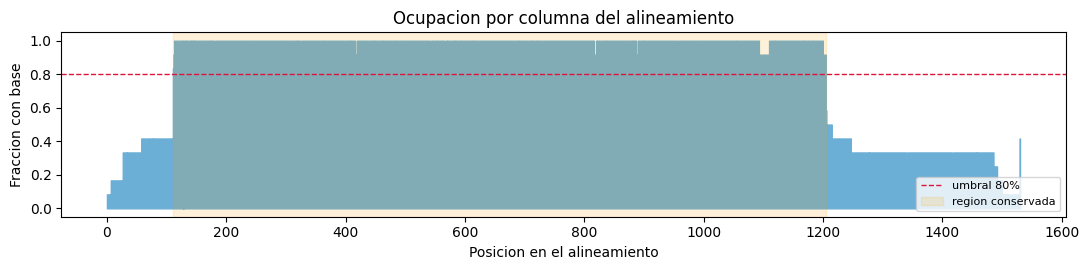

In [8]:
UMBRAL_OCUPACION = 0.8

L = alin.get_alignment_length()
n = len(alin)

# Para cada columna cuento que fraccion de secuencias tiene una base (no hueco ni N).
ocupacion = np.array([
    sum(1 for reg in alin if reg.seq[i] not in "-.nN") / n
    for i in range(L)
])

columnas_ok = np.where(ocupacion >= UMBRAL_OCUPACION)[0]
ini, fin = columnas_ok.min(), columnas_ok.max() + 1

alin_rec = alin[:, int(ini):int(fin)]
print(f"Alineamiento original: {L} columnas")
print(f"Region comun (>={UMBRAL_OCUPACION:.0%} ocupacion): columnas {ini} a {fin}")
print(f"Alineamiento recortado: {alin_rec.get_alignment_length()} columnas")

fig, ax = plt.subplots(figsize=(11, 2.8))
ax.fill_between(range(L), ocupacion, color="#6baed6", step="mid")
ax.axhline(UMBRAL_OCUPACION, color="crimson", ls="--", lw=1,
           label=f"umbral {UMBRAL_OCUPACION:.0%}")
ax.axvspan(ini, fin, color="orange", alpha=0.15, label="region conservada")
ax.set_xlabel("Posicion en el alineamiento")
ax.set_ylabel("Fraccion con base")
ax.set_title("Ocupacion por columna del alineamiento")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("figuras/ocupacion_alineamiento.png", dpi=150)
plt.show()

### 4.2 Cuántas posiciones son realmente informativas

Antes de construir el árbol vale la pena preguntarse cuánta señal hay. Una columna donde todas las
secuencias tienen la misma base no aporta nada a la filogenia. Cuento cuántas columnas son variables
y cuántas son informativas para parsimonia, es decir que tienen al menos dos bases distintas
presentes en al menos dos secuencias cada una.

In [9]:
from collections import Counter

Lr = alin_rec.get_alignment_length()
variables, informativas = [], []

for i in range(Lr):
    col = [str(reg.seq[i]).upper() for reg in alin_rec]
    bases = [b for b in col if b in "ACGT"]
    if len(bases) < 4:
        continue
    cuenta = Counter(bases)
    if len(cuenta) > 1:
        variables.append(i)
        if sum(1 for v in cuenta.values() if v >= 2) >= 2:
            informativas.append(i)

print(f"Posiciones en el alineamiento recortado : {Lr}")
print(f"Posiciones variables                    : {len(variables)}  ({len(variables)/Lr:.1%})")
print(f"Posiciones informativas para parsimonia : {len(informativas)}  ({len(informativas)/Lr:.1%})")

Posiciones en el alineamiento recortado : 1094
Posiciones variables                    : 74  (6.8%)
Posiciones informativas para parsimonia : 21  (1.9%)


## 5. Matriz de distancias con el modelo Kimura 2-parámetros

El paper cabecera usa el modelo de dos parámetros de Kimura (K2P). La idea del modelo es que no
todas las sustituciones son igual de frecuentes: las **transiciones** (purina por purina, A<->G, o
pirimidina por pirimidina, C<->T) ocurren mucho más seguido que las **transversiones** (purina por
pirimidina). Contar simplemente cuántas posiciones difieren, como hace la distancia de identidad,
trata a los dos tipos de cambio por igual y subestima la distancia real cuando hay saturación.

La fórmula de Kimura (1980) corrige esto:

$$d_{K2P} = -\frac{1}{2}\ln\left[(1-2P-Q)\sqrt{1-2Q}\right]$$

donde $P$ es la proporción de sitios con transición y $Q$ la proporción de sitios con transversión.

Biopython no trae K2P entre sus modelos para ADN, así que lo implemento a mano. Es una función corta
y me asegura usar exactamente el mismo modelo que el paper con el que quiero comparar.

In [10]:
TRANSICIONES = {("A", "G"), ("G", "A"), ("C", "T"), ("T", "C")}

def distancia_k2p(s1, s2):
    """Distancia Kimura 2-parametros entre dos secuencias alineadas.

    Ignora las posiciones donde alguna de las dos tiene hueco o base ambigua
    (borrado por pares). Devuelve la distancia p si la formula no esta definida,
    que es lo que pasa cuando las secuencias estan muy saturadas.
    """
    comparados = transiciones = transversiones = 0

    for a, b in zip(str(s1).upper(), str(s2).upper()):
        if a not in "ACGT" or b not in "ACGT":
            continue
        comparados += 1
        if a == b:
            continue
        if (a, b) in TRANSICIONES:
            transiciones += 1
        else:
            transversiones += 1

    if comparados == 0:
        return 1.0

    P = transiciones / comparados
    Q = transversiones / comparados

    termino_1 = 1 - 2 * P - Q
    termino_2 = 1 - 2 * Q
    if termino_1 <= 0 or termino_2 <= 0:
        return (transiciones + transversiones) / comparados   # fallback: distancia p

    d = -0.5 * np.log(termino_1 * np.sqrt(termino_2))
    # Cuando dos secuencias son identicas la formula da -0.0 por como redondea el
    # punto flotante. Una distancia negativa no tiene sentido, asi que la llevo a 0.
    return max(0.0, d)


nombres = [reg.id for reg in alin_rec]
k = len(nombres)

# Biopython quiere la matriz como lista de listas triangular inferior.
triangular = []
for i in range(k):
    fila = [distancia_k2p(alin_rec[i].seq, alin_rec[j].seq) for j in range(i + 1)]
    triangular.append(fila)

matriz_dist = DistanceMatrix(names=nombres, matrix=triangular)

# La paso a DataFrame para poder mirarla comoda.
D = pd.DataFrame(
    [[matriz_dist[a, b] for b in nombres] for a in nombres],
    index=nombres, columns=nombres
)
D.to_csv("datos/matriz_distancias_k2p.csv")

print("Matriz de distancias K2P (x1000 para que se lea mejor):\n")
print((D * 1000).round(2).to_string())

Matriz de distancias K2P (x1000 para que se lea mejor):

                          CLas_Florida_genoma  ARG_340_Wanda_2015  ARG_424_Delicia_2015  ARG_81_Andresito_2014  CLaf_capensis  CLaf_Sudafrica_Nelspruit  ARG_415_Iguazu_2015  CLam_Brasil  CLas_India_Poona  ARG_351_Wanda_2015  ARG_599_Delicia_2016  ARG_402_Iguazu_2015
CLas_Florida_genoma                      0.00                3.71                  0.93                   6.50          27.30                     20.82                 1.85        38.71              4.67                1.85                  2.78                 0.93
ARG_340_Wanda_2015                       3.71                0.00                  2.78                   3.71          29.33                     22.77                 3.71        38.75              6.55                3.71                  2.78                 2.80
ARG_424_Delicia_2015                     0.93                2.78                  0.00                   5.57          26.30                 

### 5.1 Distancias dentro y entre especies

La matriz completa es difícil de leer de un vistazo. Lo que me interesa es comparar dos cosas:
cuánto difieren entre sí las secuencias de *Ca.* L. asiaticus (incluidas las siete argentinas), y
cuánto difieren esas de las otras dos especies. Si el 16S sirviera para distinguir cepas, debería
haber variación apreciable dentro del grupo asiaticus.

Distancias K2P:

Dentro de Ca. L. asiaticus                 n= 36   min=0.00000  media=0.00341  max=0.00937
Entre especies distintas                   n= 29   min=0.01612  media=0.03028  max=0.04607

Las distancias entre especies son en promedio 9 veces mas grandes que las distancias dentro de asiaticus.


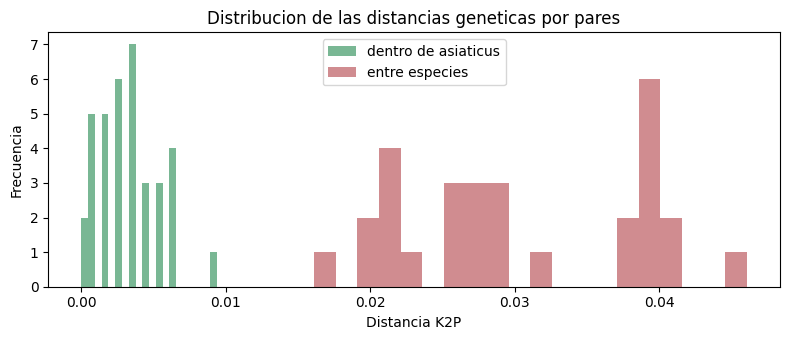

In [11]:
grupo = {}
for nombre in nombres:
    if nombre.startswith("ARG_") or nombre.startswith("CLas_"):
        grupo[nombre] = "asiaticus"
    elif nombre.startswith("CLaf_"):
        grupo[nombre] = "africanus"
    else:
        grupo[nombre] = "americanus"

intra_as, entre_especies = [], []
for i in range(k):
    for j in range(i + 1, k):
        a, b = nombres[i], nombres[j]
        d = D.loc[a, b]
        if grupo[a] == grupo[b] == "asiaticus":
            intra_as.append(d)
        elif grupo[a] != grupo[b]:
            entre_especies.append(d)

def resumen(v, etiqueta):
    v = np.array(v)
    print(f"{etiqueta:<42} n={len(v):>3}   "
          f"min={v.min():.5f}  media={v.mean():.5f}  max={v.max():.5f}")

print("Distancias K2P:\n")
resumen(intra_as, "Dentro de Ca. L. asiaticus")
resumen(entre_especies, "Entre especies distintas")

print(f"\nLas distancias entre especies son en promedio "
      f"{np.mean(entre_especies)/max(np.mean(intra_as), 1e-9):.0f} veces mas grandes "
      f"que las distancias dentro de asiaticus.")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(intra_as, bins=20, alpha=0.75, label="dentro de asiaticus", color="#4c9f70")
ax.hist(entre_especies, bins=20, alpha=0.75, label="entre especies", color="#c1666b")
ax.set_xlabel("Distancia K2P")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribucion de las distancias geneticas por pares")
ax.legend()
plt.tight_layout()
plt.savefig("figuras/distribucion_distancias.png", dpi=150)
plt.show()

## 6. Árbol filogenético por Neighbor-Joining

Neighbor-Joining es un método de agrupamiento que parte de la matriz de distancias y va uniendo
iterativamente los pares de taxones que minimizan la longitud total del árbol. Es el mismo método
del paper cabecera.

Un punto que importa: NJ produce un árbol **sin raíz**. Si lo dibujo tal cual, la ubicación de la
raíz es arbitraria y uno tiende a leer relaciones evolutivas que el árbol no está afirmando. Por eso
lo enraízo con un **grupo externo**: uso *Ca.* L. americanus, que es la especie más divergente del
conjunto, como punto de anclaje.

In [12]:
constructor = DistanceTreeConstructor()
arbol = constructor.nj(matriz_dist)

# Enraizo con el grupo externo.
arbol.root_with_outgroup({"name": GRUPO_EXTERNO})

# NJ puede devolver longitudes de rama negativas por ruido en las distancias.
# No tienen sentido biologico, asi que las llevo a cero.
for clado in arbol.find_clades():
    if clado.branch_length is not None and clado.branch_length < 0:
        clado.branch_length = 0.0

# Los nodos internos vienen con nombres automaticos tipo "Inner1" que ensucian el dibujo.
for clado in arbol.find_clades():
    if clado.name and clado.name.startswith("Inner"):
        clado.name = None

Phylo.write(arbol, "datos/arbol_16S.nwk", "newick")
print("Arbol guardado en formato Newick.\n")
Phylo.draw_ascii(arbol)

Arbol guardado en formato Newick.

                                          , ARG_402_Iguazu_2015
                                         ,|
                                         || ARG_351_Wanda_2015
                                         |
                                         | CLas_Florida_genoma
                                         |
                                         | ARG_415_Iguazu_2015
                                         |
                                        ,| ARG_424_Delicia_2015
                                        ||
                                        ||, ARG_599_Delicia_2016
                                        |||
                                 _______| | ___ ARG_81_Andresito_2014
                                |       | ||
                                |       |  | ARG_340_Wanda_2015
  ______________________________|       |
 |                              |       |_ CLas_India_Poona
 |                              |
_|      

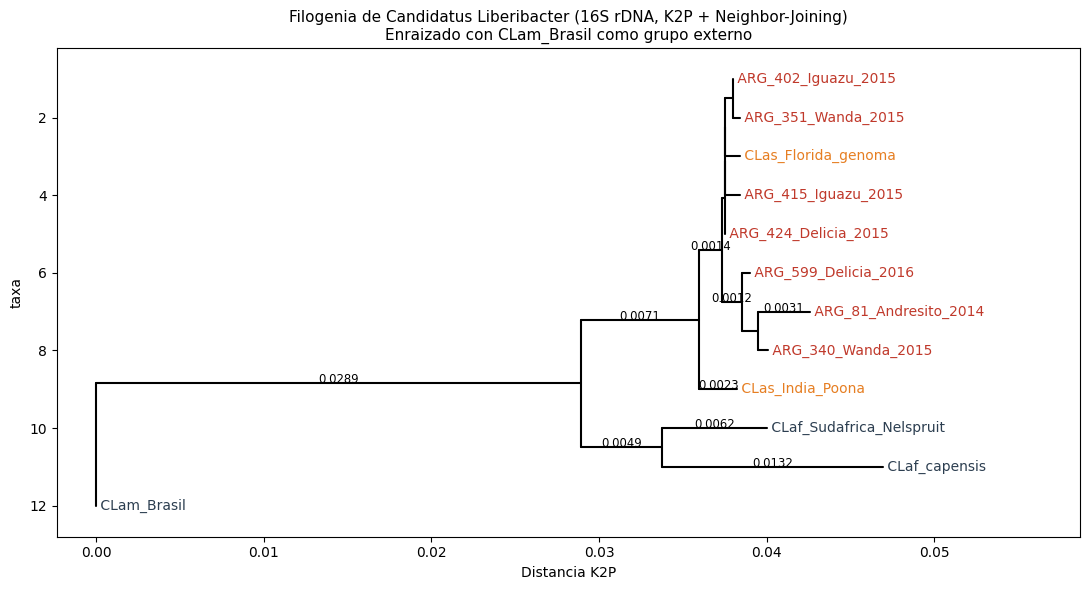

In [13]:
# Ojo: Biopython le pasa a esta funcion el TEXTO de la hoja, no el objeto clado.
def color_hoja(etiqueta):
    etiqueta = str(etiqueta)
    if etiqueta.startswith("ARG_"):
        return "#c0392b"      # argentinas en rojo
    if etiqueta.startswith("CLas_"):
        return "#e67e22"      # otras asiaticus en naranja
    return "#2c3e50"

fig, ax = plt.subplots(figsize=(11, 6))
Phylo.draw(arbol, axes=ax, do_show=False,
           label_colors=color_hoja,
           branch_labels=lambda c: f"{c.branch_length:.4f}"
                                   if c.branch_length and c.branch_length > 0.001 else None)
ax.set_title("Filogenia de Candidatus Liberibacter (16S rDNA, K2P + Neighbor-Joining)\n"
             f"Enraizado con {GRUPO_EXTERNO} como grupo externo", fontsize=11)
ax.set_xlabel("Distancia K2P")
plt.tight_layout()
plt.savefig("figuras/arbol_filogenetico.png", dpi=150)
plt.show()

### Conclusión parcial del bloque 1

El árbol separa con claridad las tres especies de *Candidatus* Liberibacter, y los números
acompañan: la distancia K2P media entre especies distintas es de 0,0303, unas **9 veces mayor** que
la distancia media dentro de *Ca.* L. asiaticus, que es de 0,0034. Los dos rangos ni siquiera se
tocan: la mayor distancia dentro de asiaticus (0,0094) es menor que la menor distancia entre
especies (0,0161). Esa separación limpia es la que hace del 16S un buen marcador de diagnóstico.

Dentro del grupo asiaticus pasa otra cosa. Las siete secuencias argentinas quedaron agrupadas, pero
**no forman un clado propio**: la secuencia de referencia de Florida (CP019958) quedó ubicada entre
ellas, y la de India aparece como su pariente más cercano. Es decir que una cepa de Estados Unidos
es genéticamente indistinguible de las argentinas en este marcador. Tampoco hay agrupamiento por
localidad, por hospedante ni por año de muestreo: las dos muestras de Wanda no están más cerca entre
sí que de las de Iguazú, y las de limón no se separan de las de naranja o pomelo.

Conviene ser preciso sobre cuánta variación hay realmente, porque "no resuelve" no significa "no hay
diferencias". De las 1094 posiciones del alineamiento recortado, 74 son variables (un 6,8%) pero
solo 21 son informativas para parsimonia (1,9%). O sea que sí existen diferencias puntuales entre
secuencias, pero son pocas y no se organizan geográficamente.

Esto coincide con lo que reportaron Badaracco y colaboradores, que también encontraron que las
secuencias argentinas no formaban un grupo monofilético. Y coincide con lo que se sabe del marcador:
el análisis del 16S de CLas en 214 muestras en la península de Yucatán identificó un haplotipo
principal con distribución mundial y 100% de similitud dentro del grupo.

La conclusión es metodológica y hay que decirla con precisión: **el 16S rDNA resuelve el nivel de
especie pero no el de cepa en *Ca.* L. asiaticus**.

Acá es importante no pasarse de lo que los datos permiten afirmar. Que el marcador no distinga cepas
**no significa que la bacteria sea genéticamente uniforme**. Son dos cosas distintas: lo que mostré
es que esta región del genoma tiene demasiada poca variación (74 posiciones variables y solo 21
informativas sobre 1094) como para separar poblaciones. Si las poblaciones de CLas difieren o no
entre sí es una pregunta que este análisis **no puede contestar**, en ningún sentido. Haría falta
mirar loci más variables, como el operón *rplKAJL-rpoBC*, o directamente genomas completos.
Confundir "el marcador no discrimina" con "no hay nada que discriminar" sería tomar la ausencia de
evidencia como evidencia de ausencia.

Dicho eso, el resultado tiene dos consecuencias concretas.

La primera es práctica y se relaciona con el contexto de vigilancia. El 16S es el marcador adecuado
para **confirmar la presencia** de la bacteria, que es justamente lo que necesita el monitoreo
fitosanitario y lo que hace la nested-PCR del protocolo. No sirve, en cambio, para rastrear el
origen geográfico de una introducción ni para caracterizar poblaciones locales.

La segunda es la que organiza el resto del trabajo. Como con este marcador no puedo caracterizar el
genotipo del patógeno, **con datos de campo no podría separar qué parte de la respuesta de una planta
se debe a la bacteria y qué parte al hospedante**: las dos cosas variarían al mismo tiempo y no
tendría forma de distinguirlas. Para responder la pregunta central necesito entonces un experimento
donde el patógeno esté **controlado por diseño**, y no inferido.

GSE30502 es exactamente eso. Los dos genotipos se inocularon por injerto con tejido infectado en el
mismo ensayo, en invernadero y bajo las mismas condiciones, con plantas control injertadas con
tejido sano. El patógeno deja de ser una variable y pasa a ser una constante del diseño, así que
cualquier diferencia en la respuesta es atribuible al hospedante. Ese razonamiento no depende de
ninguna suposición sobre la diversidad de CLas: depende del diseño del experimento.

Con eso resuelto, el bloque 2 puede ir directo a la pregunta central.

---

# BLOQUE 2 - Minería de datos sobre la respuesta transcripcional del hospedante

## 7. Descarga y armado de la matriz de expresión

GEO distribuye cada serie en un archivo llamado *series matrix*, que es un texto plano con dos
partes: un encabezado con los metadatos de cada muestra (líneas que empiezan con `!`) y después la
tabla de expresión propiamente dicha, con las sondas en las filas y las muestras en las columnas.

Lo descargo y lo parseo a mano en vez de usar una librería, así queda explícito de dónde sale cada
cosa.

In [14]:
GSE = "GSE30502"
URL = f"https://ftp.ncbi.nlm.nih.gov/geo/series/{GSE[:-3]}nnn/{GSE}/matrix/{GSE}_series_matrix.txt.gz"

destino_gz = f"datos/{GSE}_series_matrix.txt.gz"
destino    = f"datos/{GSE}_series_matrix.txt"

if not os.path.exists(destino):
    print(f"Descargando {URL} ...")
    urllib.request.urlretrieve(URL, destino_gz)
    with gzip.open(destino_gz, "rb") as fin, open(destino, "wb") as fout:
        shutil.copyfileobj(fin, fout)
    print(f"Listo: {os.path.getsize(destino)/1e6:.1f} MB descomprimidos")
else:
    print("El archivo ya estaba descargado.")

Descargando https://ftp.ncbi.nlm.nih.gov/geo/series/GSE30nnn/GSE30502/matrix/GSE30502_series_matrix.txt.gz ...
Listo: 3.5 MB descomprimidos


In [15]:
# Separo el encabezado de metadatos de la tabla de expresion.
with open(destino, "r", encoding="utf-8", errors="replace") as f:
    lineas = f.readlines()

meta_crudo = [l.rstrip("\n") for l in lineas if l.startswith("!")]

ini_tabla = next(i for i, l in enumerate(lineas) if l.startswith("!series_matrix_table_begin"))
fin_tabla = next(i for i, l in enumerate(lineas) if l.startswith("!series_matrix_table_end"))
tabla_txt = "".join(lineas[ini_tabla + 1: fin_tabla])

expr = pd.read_csv(StringIO(tabla_txt), sep="\t", index_col=0)
expr.index.name = "sonda"
expr = expr.dropna(how="all")

print(f"Matriz cruda: {expr.shape[0]} sondas x {expr.shape[1]} muestras")
print(f"Muestras: {list(expr.columns)}")

Matriz cruda: 30395 sondas x 12 muestras
Muestras: ['GSM756545', 'GSM756546', 'GSM756547', 'GSM756548', 'GSM756549', 'GSM756550', 'GSM756551', 'GSM756552', 'GSM756553', 'GSM756554', 'GSM756555', 'GSM756556']


### 7.1 Reconstrucción de las etiquetas experimentales

Las columnas vienen identificadas con códigos GSM que no dicen nada. Necesito saber, para cada una,
qué genotipo es y si estaba infectada o no. Esa información está en el encabezado, en las líneas
`!Sample_title` y `!Sample_characteristics_ch1`.

Prefiero **derivar las etiquetas del propio archivo** en vez de escribirlas a mano. Si las escribo a
mano y me equivoco en el orden, todo el análisis posterior queda mal y no hay forma de darse cuenta.

Al mirar los metadatos de esta serie aparece algo que hay que tener en cuenta. El genotipo está
escrito con todas las letras en las características de cada muestra (`genotype: Cleopatra`,
`genotype: US-897`), pero **el tratamiento no figura en ninguna palabra**: los autores lo
codificaron en el nombre de la muestra. Los títulos tienen la forma `Cleopatra_MC1-1` o
`US-897_TI1-2`, donde:

- la primera letra es el genotipo, **M** de mandarina Cleopatra o **T** de tolerante US-897,
- la segunda es el tratamiento, **C** de control o **I** de inoculado,
- el primer número es el lote del ensayo y el segundo el número de réplica.

Así que `Cleopatra_MC1-1` es la réplica 1 de mandarina Cleopatra control, y `US-897_TI1-2` es la
réplica 2 de US-897 inoculado. El código de abajo busca primero palabras explícitas y después
completa con esa nomenclatura lo que no haya encontrado.

Esto da además una **verificación cruzada gratis**: el genotipo se puede leer de dos fuentes
independientes, el campo `genotype` y la letra del código. Si las dos no coincidieran, significaría
que entendí mal la nomenclatura, así que lo chequeo explícitamente antes de seguir.

In [16]:
def campo_meta(clave):
    """Devuelve la lista de valores de una linea de metadatos del series matrix."""
    for l in meta_crudo:
        if l.startswith(f"!{clave}"):
            partes = l.split("\t")[1:]
            return [p.strip().strip('"') for p in partes]
    return []

titulos = campo_meta("Sample_title")
geo_ids = campo_meta("Sample_geo_accession")

# Las caracteristicas pueden venir en varias lineas; las junto todas por muestra.
caracteristicas = [[] for _ in geo_ids]
for l in meta_crudo:
    if l.startswith("!Sample_characteristics_ch1"):
        vals = [p.strip().strip('"') for p in l.split("\t")[1:]]
        for i, v in enumerate(vals):
            if i < len(caracteristicas) and v:
                caracteristicas[i].append(v)

print(f"{'GSM':<12} {'TITULO':<40} CARACTERISTICAS")
print("-" * 115)
for g, t, c in zip(geo_ids, titulos, caracteristicas):
    print(f"{g:<12} {t[:38]:<40} {'; '.join(c)[:60]}")

GSM          TITULO                                   CARACTERISTICAS
-------------------------------------------------------------------------------------------------------------------
GSM756545    Cleopatra_MC1-1                          genotype: Cleopatra; type of plants: greenhouse-grown seedli
GSM756546    Cleopatra_MC1-2                          genotype: Cleopatra; type of plants: greenhouse-grown seedli
GSM756547    Cleopatra_MC1-3                          genotype: Cleopatra; type of plants: greenhouse-grown seedli
GSM756548    Cleopatra_MI1-1                          genotype: Cleopatra; type of plants: greenhouse-grown seedli
GSM756549    Cleopatra_MI1-2                          genotype: Cleopatra; type of plants: greenhouse-grown seedli
GSM756550    Cleopatra_MI1-3                          genotype: Cleopatra; type of plants: greenhouse-grown seedli
GSM756551    US-897_TC1-1                             genotype: US-897; type of plants: greenhouse-grown seedling;
GSM756552

In [17]:
# Si la deteccion automatica de abajo no acierta, se completa este diccionario a mano
# con los GSM que aparecen en la tabla anterior y listo. Formato:
#     "GSM755123": ("tolerante", "infectado"),
# Los valores validos son "tolerante"/"susceptible" y "infectado"/"control".
ETIQUETAS_MANUALES = {
}

# Las expresiones buscan el patron de CONTROL antes que el de INFECTADO, porque
# "non-infected" y "Las-negative" contienen la palabra "infect" y "las": si se
# preguntara primero por infectado, un control quedaria mal clasificado.

PATRON_CONTROL = re.compile(
    r"(control|healthy|mock|uninfect|non[- ]?infect|not[- ]?infect|"
    r"las[- ]?(negative|free)|negative|asymptomatic|untreated|sano|sin[- ]?infec)")

PATRON_INFECTADO = re.compile(
    r"(infect|inocul|diseased|symptomatic|hlb|huanglongbing|"
    r"\+\s*c?las\b|\bc?las[- ]?(positive|infected)|\bclas\b|liberibacter)")

PATRON_TOLERANTE = re.compile(r"(us[- ]?897|\b897\b|toleran|trifoliata|poncirus)")
PATRON_SUSCEPTIBLE = re.compile(r"(cleopatra|\bcleo\b|suscept)")

# Los autores no escribieron el tratamiento con palabras: lo codificaron en el nombre
# de cada muestra. Los titulos tienen la forma Cleopatra_MC1-1 o US-897_TI1-2, donde
# la primera letra es el genotipo (M de mandarina Cleopatra, T de tolerante US-897),
# la segunda es el tratamiento (C de control, I de inoculado), y los dos numeros son
# el lote del ensayo y el numero de replica.
PATRON_CODIGO = re.compile(r"_([mt])([ci])(\d+)\s*-\s*(\d+)\b")

LETRA_GENOTIPO = {"m": "susceptible", "t": "tolerante"}
LETRA_TRATAMIENTO = {"c": "control", "i": "infectado"}


def decodificar_titulo(texto):
    """Lee genotipo y tratamiento del codigo del titulo. Devuelve (None, None)
    si el titulo no sigue esa nomenclatura."""
    m = PATRON_CODIGO.search(texto.lower())
    if not m:
        return None, None
    return LETRA_GENOTIPO[m.group(1)], LETRA_TRATAMIENTO[m.group(2)]


def clasificar(texto):
    """Deduce genotipo y tratamiento de una muestra.

    Primero busca palabras explicitas en el titulo y las caracteristicas. Lo que
    no encuentre asi lo completa con el codigo del titulo.
    """
    t = texto.lower()

    if PATRON_TOLERANTE.search(t):
        genotipo = "tolerante"
    elif PATRON_SUSCEPTIBLE.search(t):
        genotipo = "susceptible"
    else:
        genotipo = "?"

    # El control se evalua antes que la infeccion a proposito: "non-infected" y
    # "Las-negative" contienen la palabra "infect", asi que preguntar primero por
    # infectado clasificaria mal a los controles.
    if PATRON_CONTROL.search(t):
        tratamiento = "control"
    elif PATRON_INFECTADO.search(t):
        tratamiento = "infectado"
    else:
        tratamiento = "?"

    g_cod, t_cod = decodificar_titulo(t)
    if genotipo == "?" and g_cod:
        genotipo = g_cod
    if tratamiento == "?" and t_cod:
        tratamiento = t_cod

    return genotipo, tratamiento


filas = []
for g, t, c in zip(geo_ids, titulos, caracteristicas):
    texto = t + " | " + " | ".join(c)
    genotipo, tratamiento = clasificar(texto)
    g_cod, t_cod = decodificar_titulo(texto)
    if g in ETIQUETAS_MANUALES:                      # la correccion manual manda
        genotipo, tratamiento = ETIQUETAS_MANUALES[g]
    filas.append({"gsm": g, "titulo": t, "genotipo": genotipo,
                  "tratamiento": tratamiento,
                  "geno_codigo": g_cod, "trat_codigo": t_cod, "texto": texto})

muestras = pd.DataFrame(filas).set_index("gsm")
muestras["grupo"] = muestras["genotipo"] + "_" + muestras["tratamiento"]

print(muestras[["titulo", "genotipo", "tratamiento"]].to_string())
print("\nDiseno experimental reconstruido:")
print(pd.crosstab(muestras["genotipo"], muestras["tratamiento"]))

                    titulo     genotipo tratamiento
gsm                                                
GSM756545  Cleopatra_MC1-1  susceptible     control
GSM756546  Cleopatra_MC1-2  susceptible     control
GSM756547  Cleopatra_MC1-3  susceptible     control
GSM756548  Cleopatra_MI1-1  susceptible   infectado
GSM756549  Cleopatra_MI1-2  susceptible   infectado
GSM756550  Cleopatra_MI1-3  susceptible   infectado
GSM756551     US-897_TC1-1    tolerante     control
GSM756552     US-897_TC1-2    tolerante     control
GSM756553     US-897_TC1-3    tolerante     control
GSM756554     US-897_TI1-1    tolerante   infectado
GSM756555     US-897_TI1-2    tolerante   infectado
GSM756556     US-897_TI1-3    tolerante   infectado

Diseno experimental reconstruido:
tratamiento  control  infectado
genotipo                       
susceptible        3          3
tolerante          3          3


Antes de seguir conviene **verificar que las etiquetas quedaron bien**. Si alguno de los dos
factores terminara con un solo nivel (por ejemplo todas las muestras como "infectado", o todas como
"?"), el resto del notebook correría con grupos vacíos y produciría resultados sin sentido: tests
estadísticos sobre conjuntos vacíos, tablas de confusión con una sola columna, comparaciones que no
comparan nada.

La celda siguiente corta la ejecución si eso pasa, y muestra el texto crudo de cada muestra para
poder completar el diccionario `ETIQUETAS_MANUALES` de arriba. Es preferible frenar acá con un
mensaje claro que arrastrar el problema veinte celdas más adelante.

In [18]:
ESPERADOS = {"genotipo": {"tolerante", "susceptible"},
             "tratamiento": {"infectado", "control"}}

problemas = []
for factor, validos in ESPERADOS.items():
    presentes = set(muestras[factor]) - {"?"}
    n_dudosas = (muestras[factor] == "?").sum()

    if n_dudosas:
        problemas.append(f"{factor}: {n_dudosas} muestras quedaron sin clasificar")
    if len(presentes) < 2:
        problemas.append(f"{factor}: solo se detecto el nivel {presentes or '{}'}, "
                         f"hacen falta los dos ({validos})")
    desconocidos = presentes - validos
    if desconocidos:
        problemas.append(f"{factor}: valores inesperados {desconocidos}")

# Verificacion cruzada: el genotipo se puede leer de dos fuentes independientes,
# el campo "genotype" de las caracteristicas y la letra del codigo del titulo.
# Si las dos no coinciden, hay algo mal entendido en la nomenclatura y conviene
# frenar antes de construir todo el analisis sobre una suposicion equivocada.
con_codigo = (muestras[muestras["geno_codigo"].notna()]
              if "geno_codigo" in muestras.columns else muestras.iloc[:0])
if len(con_codigo):
    discrepan = con_codigo[con_codigo["genotipo"] != con_codigo["geno_codigo"]]
    if len(discrepan):
        problemas.append(
            f"el genotipo del campo 'genotype' no coincide con la letra del codigo "
            f"del titulo en {len(discrepan)} muestras:\n"
            + discrepan[["titulo", "genotipo", "geno_codigo"]].to_string())
    else:
        print(f"Verificacion cruzada OK: en las {len(con_codigo)} muestras con codigo "
              f"en el titulo,\nel genotipo declarado coincide con la letra del codigo.\n")

# Tambien chequeo que las 4 celdas del diseno 2x2 esten pobladas.
if not problemas:
    conteo = pd.crosstab(muestras["genotipo"], muestras["tratamiento"])
    if min(conteo.shape) < 2 or (conteo.values == 0).any():
        problemas.append(f"hay combinaciones de genotipo y tratamiento sin "
                         f"ninguna muestra:\n{conteo}")

if problemas:
    print("LA RECONSTRUCCION DE ETIQUETAS FALLO\n" + "=" * 60)
    for p in problemas:
        print(f"  - {p}")

    print("\nTexto COMPLETO de cada muestra, para completar ETIQUETAS_MANUALES:\n")
    for g in muestras.index:
        print(f'    "{g}": ("?", "?"),')
        print(f'        # {muestras.loc[g, "texto"]}')

    print("\nQue hacer: copiar ese bloque al diccionario ETIQUETAS_MANUALES de la")
    print("celda anterior, reemplazar cada ('?', '?') por los valores que")
    print("correspondan segun el texto del comentario, y volver a ejecutar.")
    raise ValueError("Etiquetas incompletas. Ver el detalle de arriba.")

print("Etiquetas verificadas: todas las combinaciones tienen muestras,")
print("y ninguna quedo ambigua.")
print(pd.crosstab(muestras["genotipo"], muestras["tratamiento"]))

Verificacion cruzada OK: en las 12 muestras con codigo en el titulo,
el genotipo declarado coincide con la letra del codigo.

Etiquetas verificadas: todas las combinaciones tienen muestras,
y ninguna quedo ambigua.
tratamiento  control  infectado
genotipo                       
susceptible        3          3
tolerante          3          3


### 7.2 Control de calidad y normalización

Antes de analizar conviene mirar los datos crudos. Dos cosas a chequear:

La primera es la **escala**. Los datos de microarray se publican a veces en escala lineal y a veces
en log2. Los valores de intensidad lineales tienen una distribución muy asimétrica, con pocos genes
muy expresados que dominan todo. La transformación log2 la simetriza y es lo que esperan después el
PCA y las distancias euclídeas. Chequeo el máximo: si es muy grande, están en escala lineal y
transformo.

La segunda es si las muestras son **comparables entre sí**. Si una tuviera una distribución de
intensidades corrida respecto de las demás, cualquier diferencia que encuentre después podría ser un
artefacto técnico y no biología.

In [19]:
print(f"Rango de los datos crudos: {expr.min().min():.2f} a {expr.max().max():.2f}")
print(f"Mediana global: {np.nanmedian(expr.values):.2f}")

if expr.max().max() > 100:
    print("\nLos valores estan en escala lineal -> aplico log2(x+1)")
    X = np.log2(expr.clip(lower=0) + 1)
else:
    print("\nLos valores ya parecen estar en log2 -> los dejo como estan")
    X = expr.copy()

X = X.dropna()
print(f"Matriz en log2: {X.shape[0]} sondas x {X.shape[1]} muestras")

Rango de los datos crudos: 1.00 a 14.46
Mediana global: 5.47

Los valores ya parecen estar en log2 -> los dejo como estan
Matriz en log2: 30395 sondas x 12 muestras


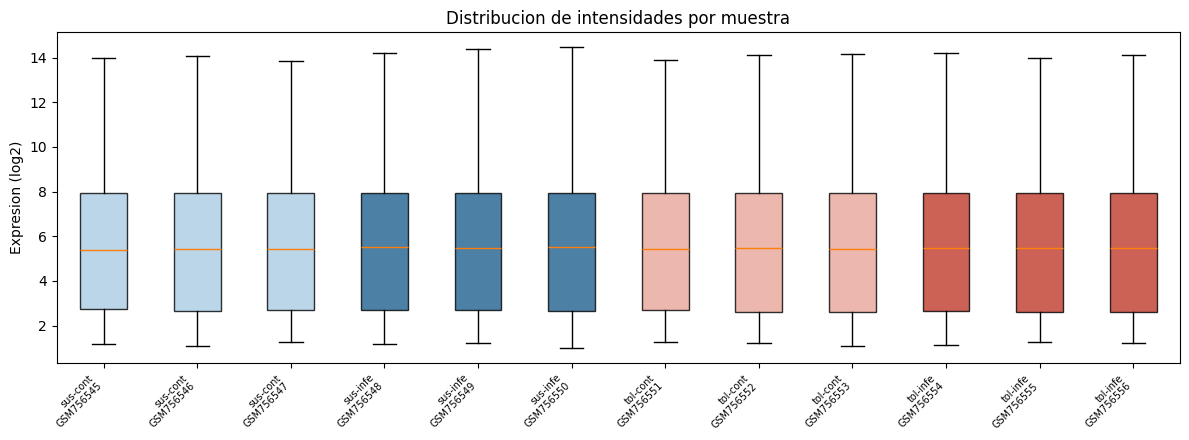

Si todas las cajas estan a la misma altura, las muestras son comparables
y no hace falta normalizar entre arrays.


In [20]:
colores = {"tolerante_infectado": "#c0392b", "tolerante_control": "#e8a598",
           "susceptible_infectado": "#1f618d", "susceptible_control": "#a9cce3"}
col_muestra = [colores.get(muestras.loc[c, "grupo"], "grey") for c in X.columns]
etiq = [f"{muestras.loc[c,'genotipo'][:3]}-{muestras.loc[c,'tratamiento'][:4]}\n{c}"
        for c in X.columns]

fig, ax = plt.subplots(figsize=(12, 4.5))
bp = ax.boxplot([X[c].values for c in X.columns],
                patch_artist=True, showfliers=False)
ax.set_xticks(range(1, len(etiq) + 1))
ax.set_xticklabels(etiq)
for parche, color in zip(bp["boxes"], col_muestra):
    parche.set_facecolor(color)
    parche.set_alpha(0.8)
ax.set_ylabel("Expresion (log2)")
ax.set_title("Distribucion de intensidades por muestra")
plt.xticks(rotation=45, ha="right", fontsize=7)
plt.tight_layout()
plt.savefig("figuras/qc_boxplots.png", dpi=150)
plt.show()

print("Si todas las cajas estan a la misma altura, las muestras son comparables")
print("y no hace falta normalizar entre arrays.")

### 7.3 Filtrado por varianza y exportación del dataset

De las decenas de miles de sondas del array, la mayoría no cambia entre condiciones. Una sonda cuya
expresión es la misma en todas las muestras no puede aportar nada a distinguir grupos, y en cambio
agrega ruido y costo computacional.

Este es el criterio que vimos en la Práctica 19: si todas las muestras tienen el mismo nivel de un
gen, su varianza es cero y ese gen no dice nada. Me quedo con las 2000 sondas de mayor varianza, que
es un corte habitual para este tipo de análisis.

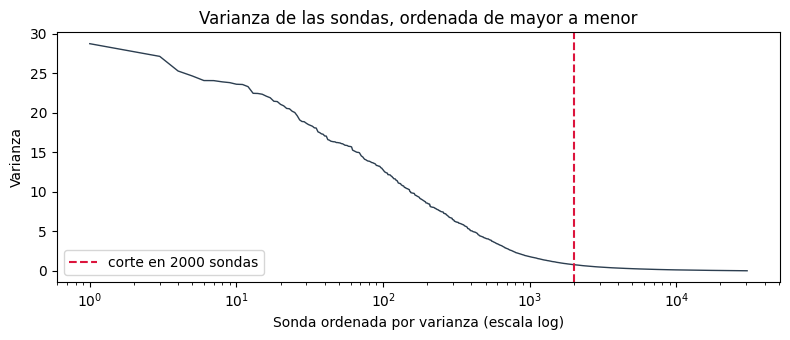

De 30395 sondas me quedo con 2000
Varianza en el corte: 0.7687 (la maxima es 28.7269)


In [21]:
N_TOP = 2000

varianzas = X.var(axis=1).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(range(1, len(varianzas) + 1), varianzas.values, lw=1, color="#2c3e50")
ax.axvline(N_TOP, color="crimson", ls="--", label=f"corte en {N_TOP} sondas")
ax.set_xscale("log")
ax.set_xlabel("Sonda ordenada por varianza (escala log)")
ax.set_ylabel("Varianza")
ax.set_title("Varianza de las sondas, ordenada de mayor a menor")
ax.legend()
plt.tight_layout()
plt.savefig("figuras/varianza_sondas.png", dpi=150)
plt.show()

sondas_top = varianzas.head(N_TOP).index
Xf = X.loc[sondas_top]

print(f"De {X.shape[0]} sondas me quedo con {Xf.shape[0]}")
print(f"Varianza en el corte: {varianzas.iloc[N_TOP-1]:.4f} "
      f"(la maxima es {varianzas.iloc[0]:.4f})")

In [22]:
# Armo el CSV que se entrega. Lo dejo con las muestras en las filas, las sondas en las
# columnas y las etiquetas adelante, que es el formato que esperan sklearn y las practicas.

datos = Xf.T.copy()
datos.insert(0, "genotipo", [muestras.loc[i, "genotipo"] for i in datos.index])
datos.insert(1, "tratamiento", [muestras.loc[i, "tratamiento"] for i in datos.index])
datos.insert(2, "grupo", [muestras.loc[i, "grupo"] for i in datos.index])
datos.index.name = "muestra"

datos.to_csv("datos_hlb.csv")
print(f"Guardado datos_hlb.csv -> {datos.shape[0]} muestras x {datos.shape[1]} columnas")
print(f"  (3 columnas de etiquetas + {Xf.shape[0]} sondas)")
datos.iloc[:, :6]

Guardado datos_hlb.csv -> 12 muestras x 2003 columnas
  (3 columnas de etiquetas + 2000 sondas)


sonda,genotipo,tratamiento,grupo,Cit.18015.1.S1_s_at,Cit.654.1.S1_x_at,Cit.21547.1.S1_s_at
muestra,,,,,,
GSM756545,susceptible,control,susceptible_control,2.03632,2.28949,12.13030
GSM756546,susceptible,control,susceptible_control,2.27484,1.89267,12.17470
GSM756547,susceptible,control,susceptible_control,1.89475,1.86593,12.23780
GSM756548,susceptible,infectado,susceptible_infectado,1.93527,1.98817,12.56340
GSM756549,susceptible,infectado,susceptible_infectado,2.51027,1.94797,12.51310
GSM756550,susceptible,infectado,susceptible_infectado,2.16173,2.34820,12.57020
GSM756551,tolerante,control,tolerante_control,12.17300,11.80090,2.53489
GSM756552,tolerante,control,tolerante_control,12.41890,12.12310,2.26883
GSM756553,tolerante,control,tolerante_control,12.44350,12.24220,2.26515


### 7.4 Anotación de las sondas

Las sondas del array se identifican con códigos del fabricante, del estilo `Cit.1234.1.S1_at`.
Esos códigos no dicen nada sobre qué gen miden. Si más adelante el Random Forest me devuelve una
lista de sondas importantes y no sé qué genes son, el resultado no es biológico: es un listado de
identificadores.

GEO publica, junto con cada plataforma, una tabla de anotación que mapea cada sonda a la secuencia
y al gen que representa. La plataforma de este experimento es **GPL5731** (Affymetrix GeneChip Citrus
Genome Array). Descargo esa tabla y la uso para traducir los códigos.

Una advertencia sobre este array en particular: los cítricos no son un organismo modelo y el chip se
diseñó a partir de ESTs, no de un genoma anotado. Así que muchas sondas no van a tener un símbolo de
gen limpio, sino una descripción del transcripto o directamente la similitud con un gen de
*Arabidopsis*. Es una limitación de la plataforma, no del análisis, pero hay que tenerla presente al
interpretar.

In [23]:
# La plataforma viene en formato SOFT. Pruebo primero la via directa de GEO y si falla
# caigo al archivo del FTP.
PLATAFORMA = "GPL5731"
ruta_plat = f"datos/{PLATAFORMA}_anotacion.txt"

urls_plat = [
    f"https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc={PLATAFORMA}"
    f"&targ=self&form=text&view=full",
    f"https://ftp.ncbi.nlm.nih.gov/geo/platforms/{PLATAFORMA[:-3]}nnn/"
    f"{PLATAFORMA}/annot/{PLATAFORMA}.annot.gz",
]

texto_plat = None
if os.path.exists(ruta_plat):
    texto_plat = open(ruta_plat, encoding="utf-8", errors="replace").read()
    print("La anotacion ya estaba descargada.")
else:
    for u in urls_plat:
        try:
            print(f"Probando {u[:70]}...")
            with urllib.request.urlopen(u, timeout=180) as r:
                crudo = r.read()
            if u.endswith(".gz"):
                crudo = gzip.decompress(crudo)
            texto_plat = crudo.decode("utf-8", errors="replace")
            if "platform_table_begin" in texto_plat:
                with open(ruta_plat, "w", encoding="utf-8") as f:
                    f.write(texto_plat)
                print("  OK")
                break
            texto_plat = None
        except Exception as e:
            print(f"  fallo: {e}")

if texto_plat is None:
    print("\nNo pude bajar la anotacion. Sigo con los identificadores de sonda.")

Probando https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GPL5731&targ=self&f...
  OK


In [24]:
# Parseo la tabla de la plataforma y armo una descripcion legible por sonda.
anotacion = pd.Series(dtype=object)

if texto_plat is not None:
    lineas_p = texto_plat.splitlines()
    i0 = next(i for i, l in enumerate(lineas_p) if l.startswith("!platform_table_begin"))
    i1 = next(i for i, l in enumerate(lineas_p) if l.startswith("!platform_table_end"))
    tabla_p = pd.read_csv(StringIO("\n".join(lineas_p[i0 + 1:i1])),
                          sep="\t", low_memory=False)
    tabla_p.columns = [c.strip() for c in tabla_p.columns]
    tabla_p = tabla_p.set_index(tabla_p.columns[0])

    print(f"Tabla de la plataforma: {tabla_p.shape[0]} sondas, "
          f"{tabla_p.shape[1]} columnas de anotacion")
    print("Columnas disponibles:", list(tabla_p.columns))

    # Elijo las columnas informativas que existan, por orden de preferencia.
    preferidas = ["Gene Symbol", "Gene Title", "Target Description",
                  "Description", "GB_ACC", "Representative Public ID", "SPOT_ID"]
    usar = [c for c in preferidas if c in tabla_p.columns]
    print("\nUso estas columnas para describir cada sonda:", usar)

    # La columna Target Description trae el texto crudo del diseño de la sonda, con
    # la forma:
    #   C37_00795 /DEF=Section:2 Forward ESTs:45 BEST NR:P07369  1e-141  Chlorophyll a-b...
    # Lo util esta despues del e-value: es la descripcion del mejor hit de BLAST.
    # Tambien hay sondas anotadas como "Transcribed locus, weakly similar to XP_...  <desc>".
    # Estas dos expresiones sacan esa parte legible y descartan el resto.
    RE_BEST_NR = re.compile(r"BEST NR:\s*\S+\s+[\d.]+e-?\d+\s+(.+)", re.I)
    RE_SIMILAR = re.compile(r"similar to\s+\S+\s+(.+)", re.I)

    SIN_VALOR = {"", "---", "nan", "none"}

    def limpio(v):
        return "" if pd.isna(v) or str(v).strip().lower() in SIN_VALOR else str(v).strip()

    def describir(fila):
        simbolo = limpio(fila.get("Gene Symbol"))
        titulo = limpio(fila.get("Gene Title"))
        target = limpio(fila.get("Target Description"))

        # 1) La mejor fuente es Gene Title, salvo cuando dice solo "Transcribed locus",
        #    que no aporta nada.
        desc = titulo if titulo.lower() not in ("transcribed locus",) else ""

        # 2) Si Gene Title no sirve, intento sacar la descripcion del hit de BLAST.
        if not desc and target:
            for patron in (RE_BEST_NR, RE_SIMILAR):
                m = patron.search(target)
                if m:
                    desc = m.group(1).strip()
                    break

        # 3) Si quedo una descripcion con la forma "similar to X <algo>", me quedo
        #    con la parte final, que es la informativa.
        m = RE_SIMILAR.search(desc)
        if m and len(m.group(1).strip()) > 3:
            desc = m.group(1).strip()

        # Limpieza final. Corto en la primera barra, corchete o campo de metadatos
        # del EST (los que tienen la forma /CLAVE=), saco el "similar to" que queda
        # colgando al principio y normalizo los espacios.
        desc = re.split(r"\s*[|\[]|\s*/[A-Z_]+=?", desc)[0]
        desc = re.sub(r"^(weakly\s+)?similar to\s+", "", desc, flags=re.I)
        desc = re.sub(r"\s+", " ", desc).strip(" .,;/")

        if simbolo and desc:
            return f"{simbolo} - {desc}"[:110]
        if desc:
            return desc[:110]
        if simbolo:
            return simbolo
        # Ultimos recursos, en orden de utilidad decreciente.
        if titulo:
            # Las sondas sin gen asignado quedan como "Transcribed locus, weakly
            # similar to <accesion> [<especie>]". No hay nombre de gen que rescatar,
            # asi que dejo constancia de eso en vez de devolver la cadena cruda.
            esp = re.search(r"\[([^\]]+)\]", titulo)
            if "transcribed locus" in titulo.lower():
                return ("Locus transcripto sin gen asignado"
                        + (f" (similar a {esp.group(1)})" if esp else ""))[:110]
            return titulo[:110]
        for c in ("GB_ACC", "Representative Public ID"):
            v = limpio(fila.get(c))
            if v:
                return f"(sin descripcion, {v})"
        return "sin anotacion"

    anotacion = tabla_p.apply(describir, axis=1)

def anotar(sonda):
    """Devuelve la descripcion de una sonda, o el propio codigo si no hay anotacion."""
    if len(anotacion) and sonda in anotacion.index:
        return anotacion[sonda]
    return "(sin anotacion)"

if len(anotacion):
    # Conviene distinguir dos cosas. Que una sonda tenga una entrada en la tabla de
    # la plataforma no significa que tenga un nombre de gen util: muchas solo dicen
    # "locus transcripto" o traen un numero de accesion sin descripcion. Cuento las
    # dos categorias por separado para no sobrevender la calidad de la anotacion.
    PLACEHOLDERS = ("sin anotacion", "sin descripcion", "Locus transcripto")

    def es_informativa(s):
        a = anotar(s)
        return not any(a.startswith(p) or a == f"({p})" for p in PLACEHOLDERS)

    n_total = len(Xf.index)
    n_util = sum(1 for s in Xf.index if es_informativa(s))

    print(f"\nDe las {n_total} sondas retenidas:")
    print(f"  con nombre o descripcion de gen : {n_util:>5}  "
          f"({n_util/n_total:.0%})")
    print(f"  sin gen asignado en el array    : {n_total - n_util:>5}  "
          f"({(n_total-n_util)/n_total:.0%})")
    if n_util < n_total:
        print("\nEse segundo grupo es la limitacion de la plataforma que mencione")
        print("arriba: el array se diseño sobre ESTs, asi que hay sondas que miden un")
        print("transcripto real pero del que no se sabe a que gen corresponde.")

    print("\nEjemplos:")
    for s in list(Xf.index)[:5]:
        print(f"  {s:<24} -> {anotar(s)[:85]}")

Tabla de la plataforma: 30395 sondas, 15 columnas de anotacion
Columnas disponibles: ['GB_ACC', 'SPOT_ID', 'Species Scientific Name', 'Annotation Date', 'Sequence Type', 'Sequence Source', 'Target Description', 'Representative Public ID', 'Gene Title', 'Gene Symbol', 'ENTREZ_GENE_ID', 'RefSeq Transcript ID', 'Gene Ontology Biological Process', 'Gene Ontology Cellular Component', 'Gene Ontology Molecular Function']

Uso estas columnas para describir cada sonda: ['Gene Symbol', 'Gene Title', 'Target Description', 'GB_ACC', 'Representative Public ID', 'SPOT_ID']

De las 2000 sondas retenidas:
  con nombre o descripcion de gen :  1704  (85%)
  sin gen asignado en el array    :   296  (15%)

Ese segundo grupo es la limitacion de la plataforma que mencione
arriba: el array se diseño sobre ESTs, asi que hay sondas que miden un
transcripto real pero del que no se sabe a que gen corresponde.

Ejemplos:
  Cit.18015.1.S1_s_at      -> Locus transcripto sin gen asignado
  Cit.654.1.S1_x_at        -

### 7.5 Estadística descriptiva

In [25]:
print("ESTADISTICA DESCRIPTIVA DEL DATASET\n" + "=" * 60)
print(f"Serie GEO                : {GSE}")
print(f"Plataforma               : Affymetrix GeneChip Citrus Genome Array")
print(f"Sondas en el array       : {expr.shape[0]}")
print(f"Sondas retenidas         : {Xf.shape[0]}")
print(f"Muestras                 : {X.shape[1]}")
print(f"Diseno                   : 2 genotipos x 2 tratamientos x 3 replicas\n")

solo_expr = datos.drop(columns=["genotipo", "tratamiento", "grupo"])
print("Expresion log2 por grupo experimental:\n")

filas_res = []
for g, idx in datos.groupby("grupo").groups.items():
    v = solo_expr.loc[idx].values.ravel()
    filas_res.append({"grupo": g, "n_muestras": len(idx), "media": v.mean(),
                      "desvio": v.std(), "minimo": v.min(), "maximo": v.max()})
resumen = pd.DataFrame(filas_res).set_index("grupo")
print(resumen.round(3).to_string())

print("\nVarianza de las sondas (sobre todas las muestras):")
va = solo_expr.var(axis=0)
print(f"  media {va.mean():.4f}   mediana {va.median():.4f}   maxima {va.max():.4f}")

ESTADISTICA DESCRIPTIVA DEL DATASET
Serie GEO                : GSE30502
Plataforma               : Affymetrix GeneChip Citrus Genome Array
Sondas en el array       : 30395
Sondas retenidas         : 2000
Muestras                 : 12
Diseno                   : 2 genotipos x 2 tratamientos x 3 replicas

Expresion log2 por grupo experimental:

                       n_muestras  media  desvio  minimo  maximo
grupo                                                           
susceptible_control             3  4.901   2.265   1.085  12.633
susceptible_infectado           3  5.405   2.545   1.162  13.177
tolerante_control               3  6.377   2.400   1.404  13.128
tolerante_infectado             3  6.589   2.302   1.333  12.817

Varianza de las sondas (sobre todas las muestras):
  media 3.5258   mediana 1.7898   maxima 28.7269


## 8. Análisis de componentes principales

El PCA resume muchas variables en pocas, quedándose con las direcciones donde los datos más se
diferencian. Con 2000 sondas no puedo visualizar nada; con dos componentes principales sí.

Lo importante acá es que el PCA es **no supervisado**: no le doy las etiquetas de genotipo ni de
tratamiento. Si al graficar las muestras en el plano PC1-PC2 aparecen separadas por grupo, eso
significa que la estructura está realmente en los datos y no la impuse yo.

In [26]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

M = solo_expr.values
escalador = StandardScaler()
M_esc = escalador.fit_transform(M)

pca = PCA()
M_pca = pca.fit_transform(M_esc)

var = pca.explained_variance_ratio_
acum = np.cumsum(var)

tabla_pca = pd.DataFrame({
    "desvio_estandar": np.sqrt(pca.explained_variance_),
    "prop_varianza": var,
    "prop_acumulada": acum,
}, index=[f"PC{i}" for i in range(1, len(var) + 1)])

print("Resumen del PCA (primeras componentes):\n")
print(tabla_pca.head(8).round(4).to_string())
print(f"\nPC1 + PC2 explican el {acum[1]:.1%} de la varianza total.")

Resumen del PCA (primeras componentes):

     desvio_estandar  prop_varianza  prop_acumulada
PC1          41.0638         0.7729          0.7729
PC2          18.9670         0.1649          0.9377
PC3           6.7193         0.0207          0.9584
PC4           5.0889         0.0119          0.9703
PC5           3.9289         0.0071          0.9774
PC6           3.2394         0.0048          0.9822
PC7           3.0411         0.0042          0.9864
PC8           2.9713         0.0040          0.9905

PC1 + PC2 explican el 93.8% de la varianza total.


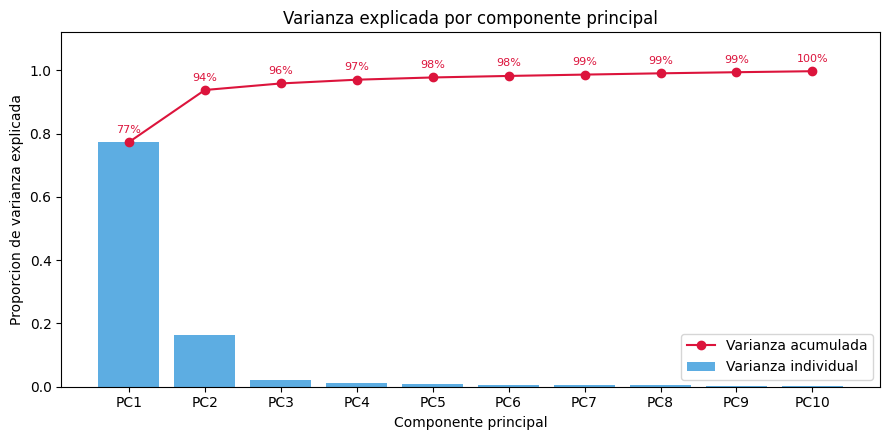

In [27]:
n_mostrar = min(10, len(var))
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(range(1, n_mostrar + 1), var[:n_mostrar], label="Varianza individual",
       color="#5dade2")
ax.plot(range(1, n_mostrar + 1), acum[:n_mostrar], marker="o", color="crimson",
        label="Varianza acumulada")
for i, a in enumerate(acum[:n_mostrar], start=1):
    ax.text(i, a + 0.03, f"{a:.0%}", ha="center", color="crimson", fontsize=8)
ax.set_xticks(range(1, n_mostrar + 1))
ax.set_xticklabels([f"PC{i}" for i in range(1, n_mostrar + 1)])
ax.set_ylim(0, 1.12)
ax.set_xlabel("Componente principal")
ax.set_ylabel("Proporcion de varianza explicada")
ax.set_title("Varianza explicada por componente principal")
ax.legend()
plt.tight_layout()
plt.savefig("figuras/pca_varianza.png", dpi=150)
plt.show()

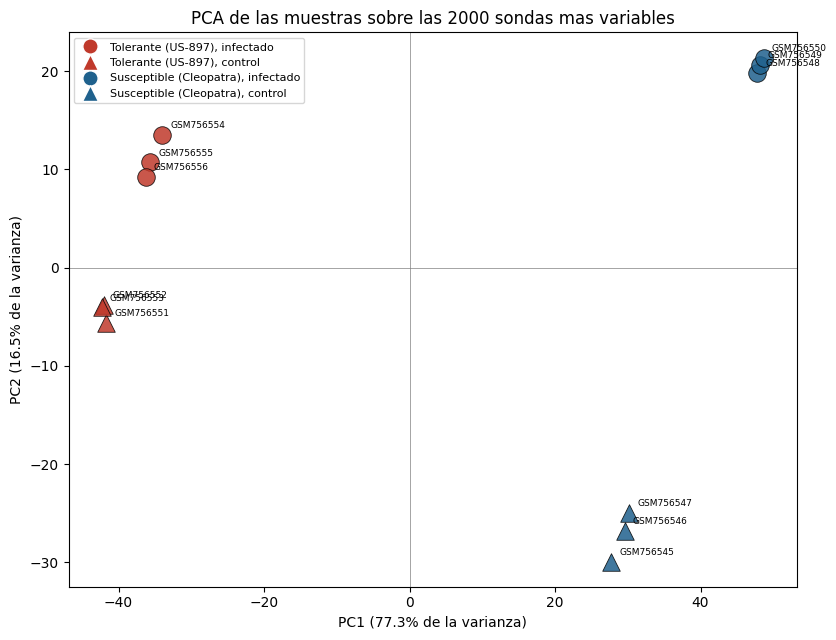

In [28]:
marcador = {"infectado": "o", "control": "^"}
color_gen = {"tolerante": "#c0392b", "susceptible": "#1f618d"}

fig, ax = plt.subplots(figsize=(8.5, 6.5))
for idx, fila in datos.iterrows():
    i = list(datos.index).index(idx)
    ax.scatter(M_pca[i, 0], M_pca[i, 1],
               c=color_gen.get(fila["genotipo"], "grey"),
               marker=marcador.get(fila["tratamiento"], "s"),
               s=160, edgecolors="black", linewidths=0.6, alpha=0.85)
    ax.annotate(idx, (M_pca[i, 0], M_pca[i, 1]), fontsize=6.5,
                xytext=(6, 5), textcoords="offset points")

from matplotlib.lines import Line2D
leyenda = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#c0392b",
           markersize=11, label="Tolerante (US-897), infectado"),
    Line2D([0], [0], marker="^", color="w", markerfacecolor="#c0392b",
           markersize=11, label="Tolerante (US-897), control"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#1f618d",
           markersize=11, label="Susceptible (Cleopatra), infectado"),
    Line2D([0], [0], marker="^", color="w", markerfacecolor="#1f618d",
           markersize=11, label="Susceptible (Cleopatra), control"),
]
ax.legend(handles=leyenda, fontsize=8, loc="best")
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel(f"PC1 ({var[0]:.1%} de la varianza)")
ax.set_ylabel(f"PC2 ({var[1]:.1%} de la varianza)")
ax.set_title("PCA de las muestras sobre las 2000 sondas mas variables")
plt.tight_layout()
plt.savefig("figuras/pca_muestras.png", dpi=150)
plt.show()

### 8.1 Qué separa cada componente

El gráfico muestra la posición de las muestras, pero no dice **por qué** están donde están. Para eso
comparo la distribución de las muestras sobre cada componente según genotipo y según tratamiento.
Así puedo decir cuál de los dos factores captura PC1 y cuál PC2, en vez de interpretarlo a ojo.

In [29]:
from scipy import stats

print("Separacion de los grupos sobre cada componente principal:\n")
print(f"{'':>5}  {'por GENOTIPO':<34}  {'por TRATAMIENTO':<34}")
print(f"{'':>5}  {'dif. medias':>12} {'p (t-test)':>12}   "
      f"{'dif. medias':>12} {'p (t-test)':>12}")
print("-" * 80)

for pc in range(min(4, M_pca.shape[1])):
    puntajes = M_pca[:, pc]
    fila = f"PC{pc+1:<4}"
    for factor, (a, b) in [("genotipo", ("tolerante", "susceptible")),
                           ("tratamiento", ("infectado", "control"))]:
        ga = puntajes[datos[factor].values == a]
        gb = puntajes[datos[factor].values == b]
        if len(ga) > 1 and len(gb) > 1:
            t, p = stats.ttest_ind(ga, gb)
            fila += f"  {ga.mean()-gb.mean():>12.2f} {p:>12.2e}"
        else:
            fila += f"  {'-':>12} {'-':>12}"
        fila += "  "
    print(fila)

print("\nNota: con 6 muestras por lado el t-test tiene poca potencia. Lo uso como")
print("orientacion sobre que factor domina cada componente, no como prueba formal.")

Separacion de los grupos sobre cada componente principal:

       por GENOTIPO                        por TRATAMIENTO                   
        dif. medias   p (t-test)    dif. medias   p (t-test)
--------------------------------------------------------------------------------
PC1           -77.31     1.02e-08           12.86     6.12e-01  
PC2             6.62     5.71e-01           31.75     2.00e-04  
PC3             0.04     9.93e-01            4.95     2.17e-01  
PC4            -0.00     1.00e+00            2.07     5.07e-01  

Nota: con 6 muestras por lado el t-test tiene poca potencia. Lo uso como
orientacion sobre que factor domina cada componente, no como prueba formal.


## 9. Clustering no supervisado

### 9.1 Clustering de las muestras

Aplico k-means y clustering jerárquico sobre las muestras, siguiendo lo visto en la Práctica 20. La
pregunta es la misma que con el PCA pero planteada de otra forma: si agrupo las muestras sin decirle
al algoritmo a qué grupo pertenecen, ¿recupera el diseño experimental?

Después evalúo la correspondencia con una tabla de confusión. Como los números de cluster que asigna
k-means son arbitrarios (el cluster 0 no tiene por qué corresponder al primer grupo), uso
`linear_sum_assignment` para encontrar la mejor correspondencia posible entre clusters y grupos
reales antes de calcular la coincidencia.

In [30]:
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import accuracy_score, adjusted_rand_score, silhouette_score

K = datos["grupo"].nunique()
print(f"Fijo k = {K}, que es la cantidad de grupos experimentales del diseno.\n")

kmeans = KMeans(n_clusters=K, random_state=SEMILLA, n_init=20)
etiq_km = kmeans.fit_predict(M_pca[:, :5])    # uso las primeras 5 PCs, no las 2000 sondas

print("Silhouette (que tan compactos y separados quedaron los clusters):")
print(f"  {silhouette_score(M_pca[:, :5], etiq_km):.3f}")
print("  (va de -1 a 1; por encima de 0.5 se considera una estructura clara)")

Fijo k = 4, que es la cantidad de grupos experimentales del diseno.

Silhouette (que tan compactos y separados quedaron los clusters):
  0.680
  (va de -1 a 1; por encima de 0.5 se considera una estructura clara)


In [31]:
def evaluar_clustering(etiquetas_pred, etiquetas_reales, titulo):
    """Tabla de confusion optimizada y coincidencia directa.

    Los numeros de cluster que asigna k-means son arbitrarios: el cluster 0 no
    tiene por que corresponder al primer grupo real. Con linear_sum_assignment
    busco la correspondencia que maximiza los aciertos antes de medir.
    """
    print(f"{titulo}\n" + "-" * len(titulo))

    tabla = pd.crosstab(pd.Series(etiquetas_pred, name="Cluster"),
                        pd.Series(etiquetas_reales, name="Grupo real"))

    n_clusters, n_grupos = tabla.shape
    if n_grupos < 2:
        print(f"La variable de referencia tiene un solo nivel "
              f"({list(tabla.columns)}), asi que no hay nada que comparar.")
        print("Revisar la reconstruccion de etiquetas de la seccion 7.1.\n")
        return np.nan, np.nan

    # linear_sum_assignment devuelve tantos pares como la dimension menor de la
    # matriz. Si hay mas clusters que grupos, algunos clusters quedan sin pareja
    # y hay que asignarlos aparte, al grupo donde mas muestras aportan.
    filas_asig, cols_asig = linear_sum_assignment(-tabla.values)
    mapa = {tabla.index[f]: tabla.columns[c] for f, c in zip(filas_asig, cols_asig)}
    for cl in tabla.index:
        if cl not in mapa:
            mapa[cl] = tabla.loc[cl].idxmax()

    if n_clusters == n_grupos:
        tabla_opt = tabla.iloc[:, cols_asig]     # reordeno para que el optimo quede en diagonal
    else:
        tabla_opt = tabla                        # no se puede diagonalizar, la muestro entera

    predicho = [mapa[c] for c in etiquetas_pred]
    coincidencia = accuracy_score(etiquetas_reales, predicho) * 100
    ari = adjusted_rand_score(etiquetas_reales, etiquetas_pred)

    print("Tabla de confusion optimizada:")
    print(tabla_opt.to_string())
    if n_clusters != n_grupos:
        print(f"\n(nota: {n_clusters} clusters contra {n_grupos} grupos reales, "
              f"la correspondencia no puede ser uno a uno)")
    print(f"\nDirect agreement : {coincidencia:.2f}%")
    print(f"Adjusted Rand Index: {ari:.3f}")
    print()
    return coincidencia, ari

reales = datos["grupo"].values
_ = evaluar_clustering(etiq_km, reales,
                       f"K-MEANS sobre los {K} grupos experimentales")

K-MEANS sobre los 4 grupos experimentales
-----------------------------------------
Tabla de confusion optimizada:
Grupo real  susceptible_infectado  tolerante_infectado  susceptible_control  tolerante_control
Cluster                                                                                       
0                               3                    0                    0                  0
1                               0                    3                    0                  0
2                               0                    0                    3                  0
3                               0                    0                    0                  3

Direct agreement : 100.00%
Adjusted Rand Index: 1.000



In [32]:
# Tambien pruebo con k=2 para cada factor por separado. Con 12 muestras y 4 grupos,
# 3 muestras por grupo es muy poco; preguntar por un solo factor a la vez es mas realista.

for factor in ["genotipo", "tratamiento"]:
    km2 = KMeans(n_clusters=2, random_state=SEMILLA, n_init=20)
    pred = km2.fit_predict(M_pca[:, :5])
    evaluar_clustering(pred, datos[factor].values,
                       f"K-MEANS con k=2, evaluado contra {factor.upper()}")

K-MEANS con k=2, evaluado contra GENOTIPO
-----------------------------------------
Tabla de confusion optimizada:
Grupo real  susceptible  tolerante
Cluster                           
0                     6          0
1                     0          6

Direct agreement : 100.00%
Adjusted Rand Index: 1.000

K-MEANS con k=2, evaluado contra TRATAMIENTO
--------------------------------------------
Tabla de confusion optimizada:
Grupo real  control  infectado
Cluster                       
0                 3          3
1                 3          3

Direct agreement : 50.00%
Adjusted Rand Index: -0.100



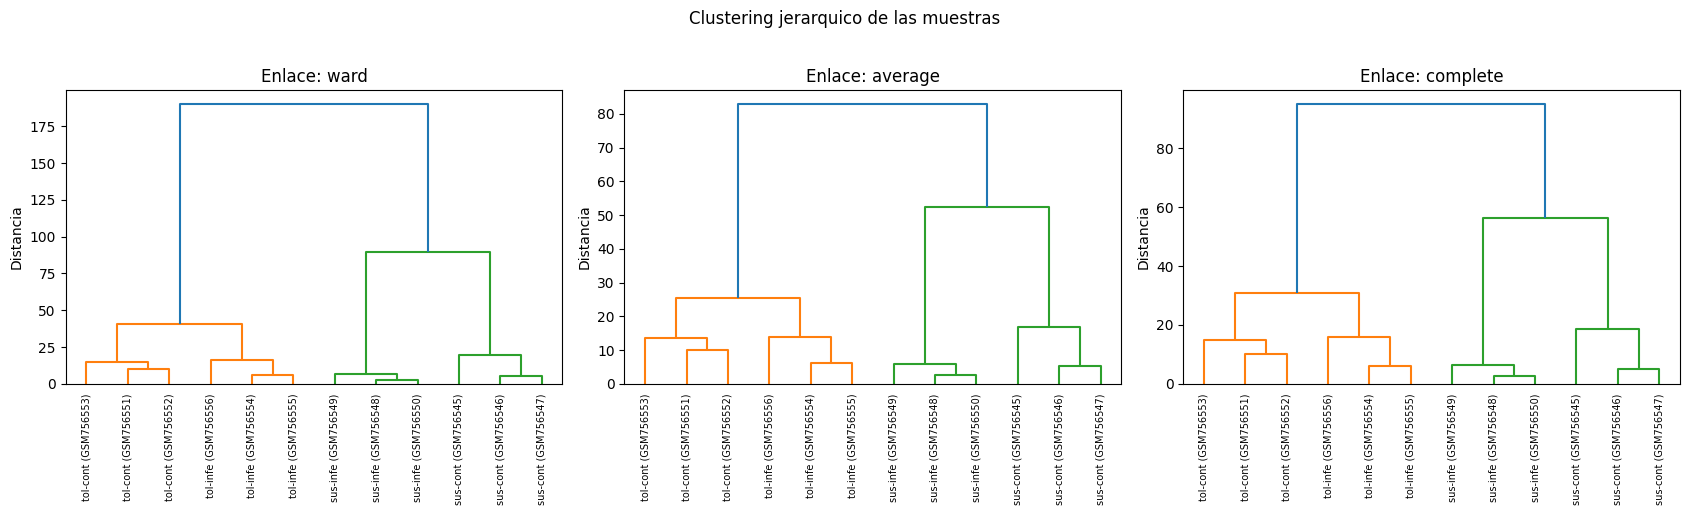

In [33]:
# Clustering jerarquico aglomerativo. Pruebo distintas estrategias de enlace
# para ver cual da una estructura mas coherente con el diseno.

etiquetas_dendro = [f"{datos.loc[i,'genotipo'][:3]}-{datos.loc[i,'tratamiento'][:4]} ({i})"
                    for i in datos.index]

estrategias = ["ward", "average", "complete"]
fig, axes = plt.subplots(1, len(estrategias), figsize=(17, 5))

for ax, metodo in zip(axes, estrategias):
    Z = linkage(M_pca[:, :5], method=metodo)
    dendrogram(Z, labels=etiquetas_dendro, ax=ax, leaf_rotation=90, leaf_font_size=7)
    ax.set_title(f"Enlace: {metodo}")
    ax.set_ylabel("Distancia")

plt.suptitle("Clustering jerarquico de las muestras", y=1.02)
plt.tight_layout()
plt.savefig("figuras/dendrogramas.png", dpi=150, bbox_inches="tight")
plt.show()

In [34]:
Z = linkage(M_pca[:, :5], method="ward")
for k_cortes, factor in [(2, "genotipo"), (2, "tratamiento"), (4, "grupo")]:
    pred = fcluster(Z, k_cortes, criterion="maxclust")
    evaluar_clustering(pred, datos[factor].values,
                       f"JERARQUICO (ward, k={k_cortes}) contra {factor.upper()}")

JERARQUICO (ward, k=2) contra GENOTIPO
--------------------------------------
Tabla de confusion optimizada:
Grupo real  tolerante  susceptible
Cluster                           
1                   6            0
2                   0            6

Direct agreement : 100.00%
Adjusted Rand Index: 1.000

JERARQUICO (ward, k=2) contra TRATAMIENTO
-----------------------------------------
Tabla de confusion optimizada:
Grupo real  control  infectado
Cluster                       
1                 3          3
2                 3          3

Direct agreement : 50.00%
Adjusted Rand Index: -0.100

JERARQUICO (ward, k=4) contra GRUPO
-----------------------------------
Tabla de confusion optimizada:
Grupo real  tolerante_control  tolerante_infectado  susceptible_infectado  susceptible_control
Cluster                                                                                       
1                           3                    0                      0                    0
2           

### 9.2 Clustering de genes

Hasta acá agrupé muestras, y son solamente 12. Hay una segunda forma de usar la misma matriz que
tiene muchas más observaciones: **transponer el problema y agrupar genes**.

En vez de preguntar qué muestras se parecen entre sí, pregunto qué genes tienen perfiles de
expresión parecidos a lo largo de las condiciones. Los genes que suben y bajan juntos suelen estar
co-regulados, o sea que participan de la misma vía o responden al mismo estímulo. Acá las
observaciones son 2000, no 12, así que el clustering tiene bastante más sustento estadístico.

In [35]:
# Estandarizo cada gen (z-score por fila) para que el agrupamiento mire la FORMA del
# perfil y no el nivel absoluto de expresion.
G = Xf.values
G_z = (G - G.mean(axis=1, keepdims=True)) / (G.std(axis=1, keepdims=True) + 1e-9)

K_GENES = 6
km_genes = KMeans(n_clusters=K_GENES, random_state=SEMILLA, n_init=20)
modulos = km_genes.fit_predict(G_z)

print(f"Agrupe {G_z.shape[0]} genes en {K_GENES} modulos de co-expresion.")
print(f"Silhouette: {silhouette_score(G_z, modulos):.3f}\n")
print("Tamano de cada modulo:")
print(pd.Series(modulos).value_counts().sort_index().to_string())

Agrupe 2000 genes en 6 modulos de co-expresion.
Silhouette: 0.493

Tamano de cada modulo:
0    1033
1      75
2     226
3      96
4     252
5     318


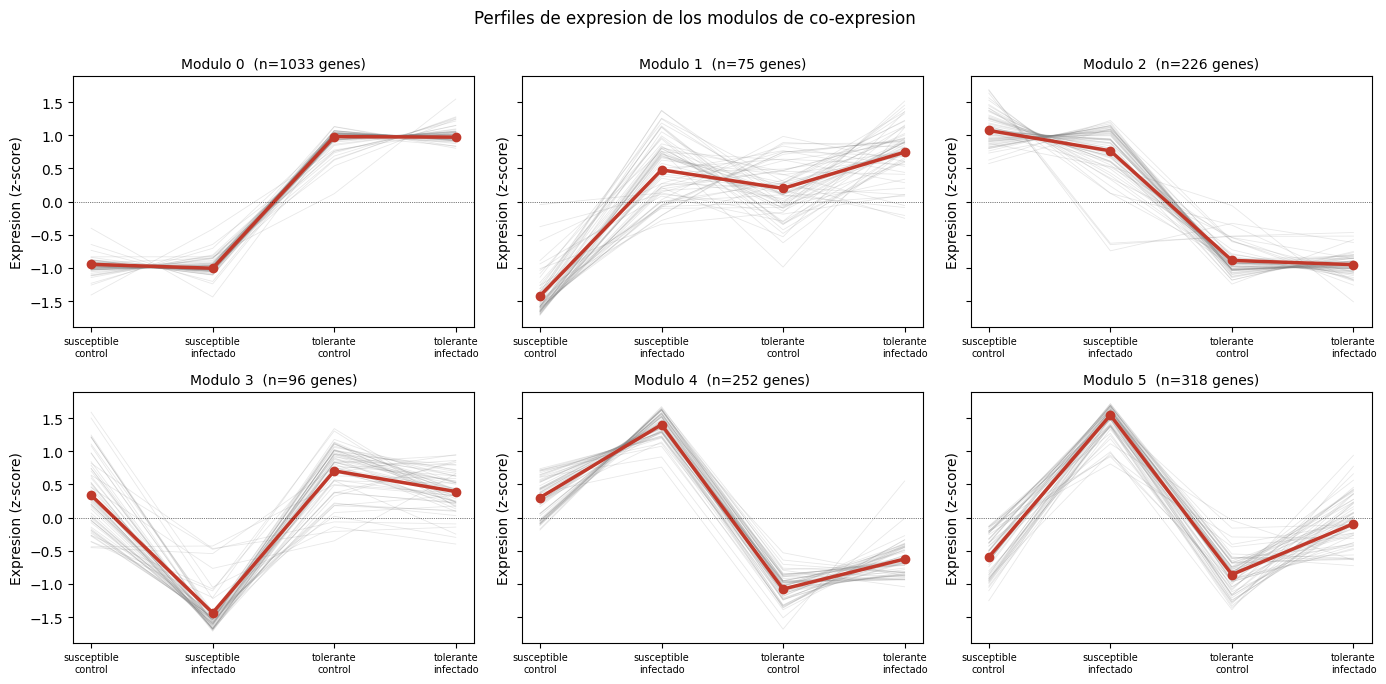

In [36]:
# Grafico el perfil promedio de cada modulo a lo largo de los 4 grupos experimentales.
orden_grupos = ["susceptible_control", "susceptible_infectado",
                "tolerante_control", "tolerante_infectado"]
orden_grupos = [g for g in orden_grupos if g in set(datos["grupo"])]

perfil = pd.DataFrame(G_z, index=Xf.index, columns=Xf.columns)
perfil_grupo = perfil.T.groupby(datos["grupo"]).mean().T[orden_grupos]

ncol = 3
nfil = int(np.ceil(K_GENES / ncol))
fig, axes = plt.subplots(nfil, ncol, figsize=(14, 3.4 * nfil), sharey=True)
axes = np.atleast_1d(axes).ravel()

for m in range(K_GENES):
    ax = axes[m]
    sub = perfil_grupo[modulos == m]
    for _, fila in sub.sample(min(60, len(sub)), random_state=SEMILLA).iterrows():
        ax.plot(range(len(orden_grupos)), fila.values, color="grey", alpha=0.18, lw=0.6)
    ax.plot(range(len(orden_grupos)), sub.mean().values,
            color="#c0392b", lw=2.5, marker="o")
    ax.axhline(0, color="black", lw=0.5, ls=":")
    ax.set_title(f"Modulo {m}  (n={ (modulos==m).sum() } genes)", fontsize=10)
    ax.set_xticks(range(len(orden_grupos)))
    ax.set_xticklabels([g.replace("_", "\n") for g in orden_grupos], fontsize=7)
    ax.set_ylabel("Expresion (z-score)")

for j in range(K_GENES, len(axes)):
    axes[j].axis("off")

plt.suptitle("Perfiles de expresion de los modulos de co-expresion", y=1.00)
plt.tight_layout()
plt.savefig("figuras/modulos_coexpresion.png", dpi=150, bbox_inches="tight")
plt.show()

### Conclusión parcial del bloque de minería

El PCA y el clustering coinciden en lo mismo: la fuente de variación dominante en estos datos es el
**genotipo**, no el tratamiento. PC1 explica por sí sola el 77,3% de la varianza y separa los
cultivares (US-897 tolerante vs. 'Cleopatra' susceptible); PC2 explica un 16,5% adicional y es la que
separa infectados de controles. Entre las dos juntan el 93,8%.

Hay un detalle del clustering que vale la pena mirar con cuidado, porque a primera vista parece una
contradicción. Con k = 2, tanto k-means como el jerárquico separan los genotipos perfectamente (100%
de coincidencia, ARI = 1) pero fracasan por completo con el tratamiento: 50% de coincidencia y un
ARI de -0,10, que es lo mismo que repartir las muestras al azar. Sin embargo, con k = 4 ambos
métodos recuperan **los cuatro grupos experimentales sin un solo error**.

La explicación es que con k = 2 el algoritmo parte los datos por la dirección de mayor variación,
que es el genotipo, y el tratamiento le queda cruzado adentro de cada mitad. No es que la señal de
infección no exista: es que queda tapada por una señal más grande. Cuando se le permite formar
cuatro grupos, aparece. Dicho de otra forma, el fracaso con k = 2 y el éxito con k = 4 son dos
lecturas del mismo hecho, que es la diferencia de magnitud entre los dos efectos.

Esto es consistente con la hipótesis de Albrecht y Bowman: la tolerancia de US-897 estaría dada por
diferencias constitutivas heredadas del parental *Poncirus trifoliata*, presentes aun sin infección,
más que por una respuesta de defensa que la infección dispare. Si la tolerancia fuera una respuesta
inducida, uno esperaría que el efecto del tratamiento pesara más de lo que pesa.

El clustering de genes agrega una lectura complementaria: los seis módulos de co-expresión tienen
perfiles bien distintos, algunos que separan genotipos y otros que responden al tratamiento, lo que
confirma que ambos efectos existen aunque tengan magnitudes muy distintas. El silhouette de 0,493
sobre 2000 genes indica una estructura moderada pero real, y acá el número se apoya en 2000
observaciones y no en 12.

---

## 10. Análisis de expresión diferencial

El clustering me dice cómo se agrupan las muestras, pero no qué genes concretos cambian. Para eso
hace falta comparar gen por gen entre condiciones, que es lo que hizo el paper cabecera.

El procedimiento es un test t por cada sonda. El problema es que hacer decenas de miles de tests
multiplica los falsos positivos: con 30.000 sondas y un umbral de p < 0,05, esperaría unos 1500
"significativos" por puro azar aunque no hubiera ninguna diferencia real. Por eso hay que corregir
por comparaciones múltiples.

Uso el procedimiento de **Benjamini-Hochberg**, que controla la tasa de falsos descubrimientos (FDR).
La idea es ordenar los p-valores de menor a mayor y comparar cada uno contra un umbral que crece con
la posición en el ranking, en vez de usar el mismo umbral para todos. Lo implemento a mano porque son
pocas líneas y así queda claro qué hace.

Esta sección además me da un **punto de comparación**: Albrecht y Bowman reportaron 326 genes con
expresión diferencial. Si mi pipeline está bien armado, debería llegar a un orden de magnitud
parecido. Es la forma de validar el análisis contra algo externo en vez de confiar en que salió bien.

In [37]:
from scipy import stats


def benjamini_hochberg(p):
    """Corrige una lista de p-valores por tasa de falsos descubrimientos (FDR).

    Ordena los p de menor a mayor, los multiplica por n/i y despues fuerza que la
    secuencia sea monotona creciente (cada valor no puede ser menor que el anterior
    mirando desde el final).
    """
    p = np.asarray(p, dtype=float)
    n = len(p)
    orden = np.argsort(p)
    p_ord = p[orden]

    q_ord = p_ord * n / np.arange(1, n + 1)
    q_ord = np.minimum.accumulate(q_ord[::-1])[::-1]   # monotonia
    q_ord = np.clip(q_ord, 0, 1)

    q = np.empty(n)
    q[orden] = q_ord
    return q


def expresion_diferencial(matriz, etiquetas, grupo_a, grupo_b):
    """Test t por sonda entre dos grupos, con log2 fold change y FDR."""
    etiquetas = np.asarray(etiquetas)
    A = matriz.loc[:, etiquetas == grupo_a].values
    B = matriz.loc[:, etiquetas == grupo_b].values

    # Algunas sondas tienen valores casi idénticos en todas las muestras y scipy
    # avisa de perdida de precision al calcular el estadistico. Son sondas sin
    # variacion, que no pueden dar diferencia significativa de ninguna manera, asi
    # que su p queda en 1 y el aviso no cambia nada del resultado. Lo silencio para
    # que no ensucie la salida.
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        t, p = stats.ttest_ind(A, B, axis=1)

    p = np.nan_to_num(p, nan=1.0)

    # Desvio estandar dentro de los grupos (agrupado). Sirve para saber si una
    # comparacion detecta poco porque el efecto es chico o porque hay mucho ruido.
    sd_interno = np.sqrt((A.var(axis=1, ddof=1) + B.var(axis=1, ddof=1)) / 2)

    res = pd.DataFrame({
        "media_" + grupo_a: A.mean(axis=1),
        "media_" + grupo_b: B.mean(axis=1),
        "log2FC": A.mean(axis=1) - B.mean(axis=1),   # ya estan en log2
        "sd_interno": sd_interno,
        "t": t,
        "p": p,
        "FDR": benjamini_hochberg(p),
    }, index=matriz.index)
    return res.sort_values("p")


# Trabajo sobre TODAS las sondas, no sobre las 2000 filtradas: el filtrado por varianza
# fue para el analisis exploratorio, pero para expresion diferencial hay que mirar todo.
etq_gen = np.array([muestras.loc[c, "genotipo"] for c in X.columns])
etq_tra = np.array([muestras.loc[c, "tratamiento"] for c in X.columns])

de_genotipo = expresion_diferencial(X, etq_gen, "tolerante", "susceptible")
de_trat     = expresion_diferencial(X, etq_tra, "infectado", "control")

print(f"Sondas analizadas: {len(de_genotipo)}\n")

Sondas analizadas: 30395



In [38]:
UMBRAL_FDR = 0.05
UMBRAL_FC  = 1.0      # log2FC de 1 equivale a duplicar la expresion

def contar(res, nombre):
    sig = res[(res["FDR"] < UMBRAL_FDR) & (res["log2FC"].abs() > UMBRAL_FC)]
    sube = (sig["log2FC"] > 0).sum()
    baja = (sig["log2FC"] < 0).sum()
    solo_p = (res["p"] < 0.05).sum()
    print(f"{nombre}")
    print(f"  p < 0.05 sin corregir            : {solo_p}")
    print(f"  FDR < {UMBRAL_FDR} y |log2FC| > {UMBRAL_FC}      : {len(sig)}  "
          f"({sube} arriba, {baja} abajo)")
    return sig

print("GENES DIFERENCIALMENTE EXPRESADOS\n" + "=" * 55)
sig_gen = contar(de_genotipo, "Tolerante (US-897) vs. susceptible (Cleopatra)")
print()
sig_tra = contar(de_trat, "Infectado vs. control")

print("\n" + "-" * 55)
print("La diferencia entre los dos numeros de arriba es el mismo resultado que")
print("dieron el PCA y el clustering, ahora cuantificado gen por gen.")

GENES DIFERENCIALMENTE EXPRESADOS
Tolerante (US-897) vs. susceptible (Cleopatra)
  p < 0.05 sin corregir            : 15199
  FDR < 0.05 y |log2FC| > 1.0      : 3023  (1614 arriba, 1409 abajo)

Infectado vs. control
  p < 0.05 sin corregir            : 6341
  FDR < 0.05 y |log2FC| > 1.0      : 232  (207 arriba, 25 abajo)

-------------------------------------------------------
La diferencia entre los dos numeros de arriba es el mismo resultado que
dieron el PCA y el clustering, ahora cuantificado gen por gen.


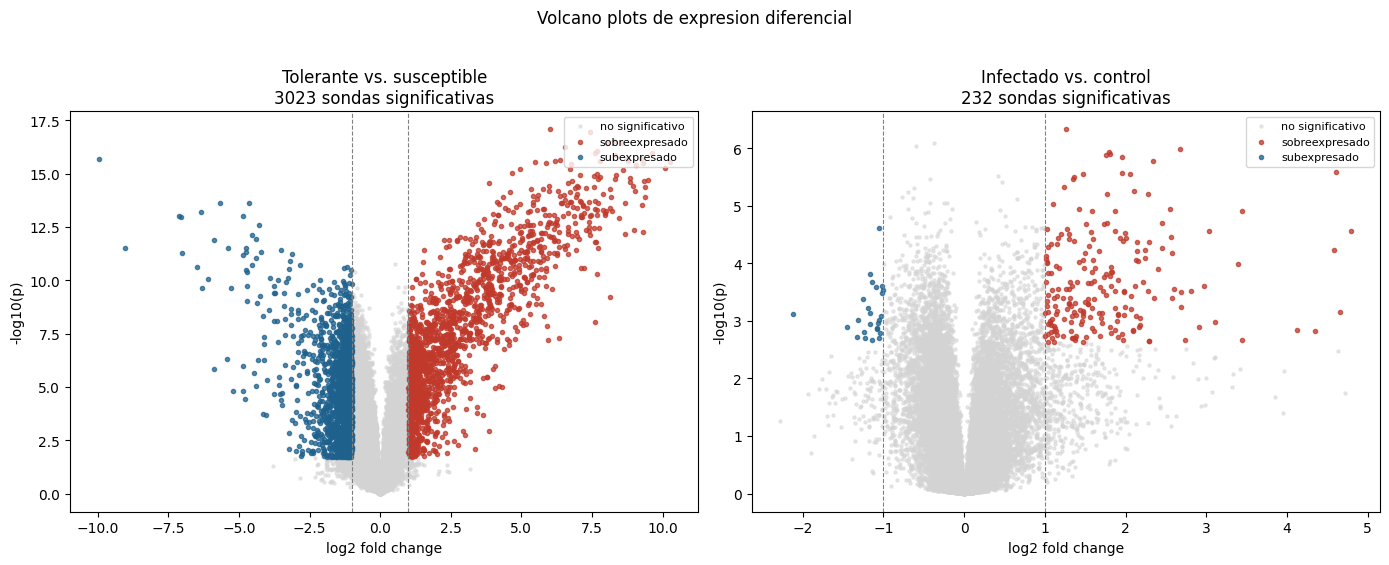

In [39]:
# Volcano plot: magnitud del cambio contra significancia estadistica.
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for ax, (res, titulo) in zip(axes, [
        (de_genotipo, "Tolerante vs. susceptible"),
        (de_trat, "Infectado vs. control")]):

    y = -np.log10(np.clip(res["p"].values, 1e-300, None))
    x = res["log2FC"].values
    sig = (res["FDR"].values < UMBRAL_FDR) & (np.abs(x) > UMBRAL_FC)

    ax.scatter(x[~sig], y[~sig], s=5, c="lightgrey", alpha=0.5, label="no significativo")
    ax.scatter(x[sig & (x > 0)], y[sig & (x > 0)], s=9, c="#c0392b", alpha=0.75,
               label="sobreexpresado")
    ax.scatter(x[sig & (x < 0)], y[sig & (x < 0)], s=9, c="#1f618d", alpha=0.75,
               label="subexpresado")

    ax.axvline(UMBRAL_FC, color="grey", ls="--", lw=0.8)
    ax.axvline(-UMBRAL_FC, color="grey", ls="--", lw=0.8)
    ax.set_xlabel("log2 fold change")
    ax.set_ylabel("-log10(p)")
    ax.set_title(f"{titulo}\n{sig.sum()} sondas significativas")
    ax.legend(fontsize=8, loc="upper right")

plt.suptitle("Volcano plots de expresion diferencial", y=1.02)
plt.tight_layout()
plt.savefig("figuras/volcano.png", dpi=150, bbox_inches="tight")
plt.show()

In [40]:
# Las sondas mas diferenciales, ahora con su anotacion.
def tabla_top(sig, n=15):
    t = sig.head(n)[["log2FC", "p", "FDR"]].copy()
    t.insert(0, "gen", [anotar(s)[:70] for s in t.index])
    t["log2FC"] = t["log2FC"].round(3)
    t["p"]   = t["p"].map(lambda v: f"{v:.2e}")
    t["FDR"] = t["FDR"].map(lambda v: f"{v:.2e}")
    return t

print("TOP 15 sondas entre genotipos (tolerante vs. susceptible)\n")
print(tabla_top(sig_gen).to_string())

print("\n\nTOP 15 sondas entre tratamientos (infectado vs. control)\n")
if len(sig_tra):
    print(tabla_top(sig_tra).to_string())
else:
    print("Ninguna sonda supero los umbrales para este contraste.")
    print("Muestro igual las 15 de menor p-valor sin corregir:\n")
    print(tabla_top(de_trat).to_string())

TOP 15 sondas entre genotipos (tolerante vs. susceptible)

                                                                    gen  log2FC         p       FDR
sonda                                                                                              
Cit.13318.1.S1_at                                          PP1A protein   6.006  8.51e-18  1.78e-13
Cit.13808.1.S1_at               peroxisomal targeting signal-1 receptor   7.432  1.17e-17  1.78e-13
Cit.28410.1.S1_at                           (sin descripcion, CV706686)   8.268  2.84e-17  2.32e-13
Cit.9771.1.S1_s_at                    GloEL protein; chaperonin, 60 kDa   8.565  3.54e-17  2.32e-13
Cit.1300.1.S1_at                                              At4g24220   8.025  3.81e-17  2.32e-13
Cit.11992.1.S1_at                                             AT3g51050   6.527  5.52e-17  2.80e-13
Cit.11617.1.S1_at                       lethal leaf spot 1-like protein   7.695  8.75e-17  3.68e-13
Cit.944.1.S1_at      adhesive/proline-ric

### 10.1 Comparación con el paper cabecera

Albrecht y Bowman reportaron **326 genes** con expresión diferencial. Para usar ese número como
referencia hay que tener claro **a qué contraste corresponde**: es la respuesta a la infección, o
sea la comparación entre plantas inoculadas y controles. No es la diferencia entre los dos genotipos.

Esa distinción importa porque mis dos contrastes dan números muy distintos. El de tratamiento es el
comparable con los 326 del paper. El de genotipo mide otra cosa: cuánto difieren entre sí dos
cultivares distintos, que son dos plantas genéticamente diferentes, y es esperable que ahí haya
muchos más genes involucrados.

La comparación tampoco puede ser exacta, por dos motivos. Ellos partieron de los archivos CEL crudos
y los normalizaron con el método propio de Affymetrix, mientras que yo trabajo sobre la matriz ya
procesada que publica GEO. Y mis umbrales (FDR < 0,05 con |log2FC| > 1) no son necesariamente los
que usaron ellos. Dos pipelines distintos sobre los mismos datos no tienen por qué dar listas
idénticas.

Lo que sí espero, si el análisis está bien armado, es que el contraste de tratamiento caiga en el
**mismo orden de magnitud** que los 326 del paper.

In [41]:
print("COMPARACION CON EL PAPER\n" + "=" * 60)
print("Albrecht y Bowman (2012) reportan 326 genes en RESPUESTA A LA INFECCION.\n")

print(f"  Contraste comparable (infectado vs control) : {len(sig_tra)} sondas")
if len(sig_tra):
    razon = len(sig_tra) / 326
    if 0.2 <= razon <= 5:
        print(f"    -> mismo orden de magnitud que el paper (x{razon:.2f})")
    else:
        print(f"    -> orden de magnitud distinto (x{razon:.2f}), conviene revisar")
else:
    print("    -> ninguna sonda supero los umbrales")

print(f"\n  Contraste de genotipo (tolerante vs susceptible) : {len(sig_gen)} sondas")
print("    -> NO es comparable con los 326: mide la diferencia entre dos cultivares")
print("       distintos, no la respuesta a la infeccion.")
if len(sig_tra):
    print(f"\n  El efecto del genotipo es {len(sig_gen)/len(sig_tra):.0f} veces mas grande "
          f"que el del tratamiento.")
    print("  Esa diferencia de magnitud es el resultado central de este bloque.")

# Guardo las listas completas para que queden en el repositorio.
for nombre, res in [("genotipo", de_genotipo), ("tratamiento", de_trat)]:
    salida = res.copy()
    salida.insert(0, "gen", [anotar(s) for s in salida.index])
    salida.to_csv(f"datos/expresion_diferencial_{nombre}.csv")
    print(f"\nGuardado datos/expresion_diferencial_{nombre}.csv")

COMPARACION CON EL PAPER
Albrecht y Bowman (2012) reportan 326 genes en RESPUESTA A LA INFECCION.

  Contraste comparable (infectado vs control) : 232 sondas
    -> mismo orden de magnitud que el paper (x0.71)

  Contraste de genotipo (tolerante vs susceptible) : 3023 sondas
    -> NO es comparable con los 326: mide la diferencia entre dos cultivares
       distintos, no la respuesta a la infeccion.

  El efecto del genotipo es 13 veces mas grande que el del tratamiento.
  Esa diferencia de magnitud es el resultado central de este bloque.

Guardado datos/expresion_diferencial_genotipo.csv

Guardado datos/expresion_diferencial_tratamiento.csv


### 10.2 La respuesta a la infección en cada genotipo por separado

**Esta es la sección que responde la pregunta central del trabajo.**

Los contrastes de la sección anterior no sirven para contestarla, y vale la pena ver por qué. El
contraste de tratamiento junta los dos genotipos y mide la respuesta promedio a la infección, con lo
cual borra justamente la diferencia que quiero encontrar. El de genotipo junta sanas e infectadas y
mide cuánto difieren dos cultivares distintos, que es otra cosa.

Lo que hace falta es separar: medir la respuesta a la infección **dentro de cada genotipo** y después
comparar las dos respuestas entre sí. Con el diseño 2x2 eso son dos contrastes de 3 contra 3:

- en 'Cleopatra' susceptible, infectadas contra sus propios controles,
- en US-897 tolerante, infectadas contra sus propios controles.

Después comparo las dos listas de tres formas. Cuántos genes responden en cada genotipo, cuánto se
solapan esas listas, y cuánto se parecen las magnitudes de cambio gen por gen. Esas tres medidas
juntas distinguen entre tres escenarios posibles, y cada uno significa algo distinto desde el punto
de vista biológico:

| Lo que se observa | Qué significa |
|---|---|
| El tolerante responde con **menos** genes y cambios más chicos | La infección lo perturba menos; la tolerancia sería capacidad de amortiguar |
| Ambos responden parecido, en genes y magnitudes | La tolerancia no está en la respuesta sino en otra parte (por ejemplo, en el estado previo) |
| Responden con genes **distintos** | La tolerancia está en activar un programa de defensa diferente |

Una advertencia sobre la potencia estadística. Cada contraste usa 3 réplicas por lado en vez de 6, así
que detecta menos genes que los de la sección anterior. Por eso no voy a interpretar los números
absolutos de genes como si fueran medidas exactas, sino la **comparación relativa** entre los dos
genotipos, que es lo que la pregunta necesita.

In [42]:
# Separo las muestras por genotipo para medir la respuesta a la infeccion dentro de
# cada uno. Son dos contrastes de 3 contra 3.
cols_susc = [c for c in X.columns if muestras.loc[c, "genotipo"] == "susceptible"]
cols_tol  = [c for c in X.columns if muestras.loc[c, "genotipo"] == "tolerante"]

trat_susc = np.array([muestras.loc[c, "tratamiento"] for c in cols_susc])
trat_tol  = np.array([muestras.loc[c, "tratamiento"] for c in cols_tol])

resp_susc = expresion_diferencial(X[cols_susc], trat_susc, "infectado", "control")
resp_tol  = expresion_diferencial(X[cols_tol],  trat_tol,  "infectado", "control")

def significativas(res):
    return set(res[(res["FDR"] < UMBRAL_FDR) &
                   (res["log2FC"].abs() > UMBRAL_FC)].index)

sig_r_susc = significativas(resp_susc)
sig_r_tol  = significativas(resp_tol)

print("RESPUESTA A LA INFECCION, DENTRO DE CADA GENOTIPO\n" + "=" * 62)
print(f"  Susceptible ('Cleopatra') : {len(sig_r_susc):>5} sondas responden")
print(f"  Tolerante   (US-897)      : {len(sig_r_tol):>5} sondas responden")

if len(sig_r_susc) and len(sig_r_tol):
    print(f"\n  Razon susceptible / tolerante: "
          f"{len(sig_r_susc)/len(sig_r_tol):.2f}")

RESPUESTA A LA INFECCION, DENTRO DE CADA GENOTIPO
  Susceptible ('Cleopatra') :  1617 sondas responden
  Tolerante   (US-897)      :     0 sondas responden


In [43]:
# 1) Cuanto se solapan las dos respuestas.
comunes_r = sig_r_susc & sig_r_tol
union_r = sig_r_susc | sig_r_tol

print("SOLAPAMIENTO ENTRE LAS DOS RESPUESTAS\n" + "=" * 62)
if union_r:
    print(f"  Solo en susceptible : {len(sig_r_susc - sig_r_tol):>5}")
    print(f"  Solo en tolerante   : {len(sig_r_tol - sig_r_susc):>5}")
    print(f"  En ambos            : {len(comunes_r):>5}")
    print(f"  Indice de Jaccard   : {len(comunes_r)/len(union_r):.3f}")
else:
    print("  Ninguna sonda supero los umbrales en ninguno de los dos genotipos.")
    print("  Con 3 replicas por lado esto puede pasar; la comparacion de magnitudes")
    print("  de la celda siguiente sigue siendo valida porque no depende del umbral.")

# 2) Magnitud del cambio: responde mas fuerte uno que el otro?
print("\nMAGNITUD DEL CAMBIO DE EXPRESION\n" + "=" * 62)
for etiqueta, res in [("Susceptible", resp_susc), ("Tolerante  ", resp_tol)]:
    fc = res["log2FC"].abs()
    print(f"  {etiqueta}: |log2FC| medio = {fc.mean():.4f}   "
          f"percentil 99 = {fc.quantile(0.99):.4f}   maximo = {fc.max():.4f}")

SOLAPAMIENTO ENTRE LAS DOS RESPUESTAS
  Solo en susceptible :  1617
  Solo en tolerante   :     0
  En ambos            :     0
  Indice de Jaccard   : 0.000

MAGNITUD DEL CAMBIO DE EXPRESION
  Susceptible: |log2FC| medio = 0.3380   percentil 99 = 2.1943   maximo = 8.9749
  Tolerante  : |log2FC| medio = 0.1705   percentil 99 = 1.0196   maximo = 4.5600


#### ¿Y si la diferencia fuera falta de potencia y no biología?

Si uno de los dos genotipos da muchos menos genes que el otro, hay dos explicaciones posibles y
conviene distinguirlas antes de interpretar nada.

La primera es que **el efecto sea realmente más chico**: la infección lo altera menos, así que los
cambios de expresión no llegan a superar el umbral.

La segunda es que **sus muestras sean más ruidosas**. Un test estadístico compara el tamaño del
efecto contra la variabilidad interna del grupo. Si las tres réplicas de un genotipo son más
dispersas entre sí, el mismo efecto queda tapado y se detectan menos genes, sin que el efecto sea
distinto.

Para separar las dos cosas miro tres indicadores. La **variabilidad interna** de cada genotipo, que
es la que determina la potencia. Y los dos criterios del filtro por separado, el estadístico (FDR) y
el de magnitud (log2FC), para ver cuál de los dos está descartando los genes. Si la variabilidad es
parecida y el que filtra es el de magnitud, entonces el efecto es genuinamente más chico.

In [44]:
print("¿EFECTO MAS CHICO O MENOS POTENCIA?\n" + "=" * 62)

print("Variabilidad interna de cada genotipo (desvio dentro de los grupos):")
for etiqueta, res in [("Susceptible", resp_susc), ("Tolerante  ", resp_tol)]:
    sd = res["sd_interno"]
    print(f"  {etiqueta}: mediana = {sd.median():.4f}   media = {sd.mean():.4f}")

razon_sd = resp_tol["sd_interno"].median() / resp_susc["sd_interno"].median()
print(f"\n  Razon tolerante / susceptible = {razon_sd:.2f}")
print("  (cerca de 1 significa que los dos genotipos son igual de reproducibles,")
print("   asi que la potencia estadistica es comparable)")

print("\nCada criterio del filtro por separado:\n")
print(f"{'':<14} {'FDR < 0.05':>12} {'|log2FC| > 1':>14} {'los dos':>10}")
print("-" * 54)
for etiqueta, res in [("Susceptible", resp_susc), ("Tolerante", resp_tol)]:
    n_fdr = int((res["FDR"] < UMBRAL_FDR).sum())
    n_fc = int((res["log2FC"].abs() > UMBRAL_FC).sum())
    n_ambos = int(((res["FDR"] < UMBRAL_FDR) &
                   (res["log2FC"].abs() > UMBRAL_FC)).sum())
    print(f"{etiqueta:<14} {n_fdr:>12} {n_fc:>14} {n_ambos:>10}")

fdr_susc = int((resp_susc["FDR"] < UMBRAL_FDR).sum())
fdr_tol  = int((resp_tol["FDR"] < UMBRAL_FDR).sum())

print("\nConclusion del chequeo:")
if not (0.6 <= razon_sd <= 1.6):
    print(f"  CUIDADO: la variabilidad interna difiere bastante (razon {razon_sd:.2f}).")
    print("  Parte de la diferencia en genes detectados puede deberse a potencia")
    print("  desigual y no solo al tamaño del efecto. Hay que decirlo al interpretar.")
else:
    print("  La variabilidad interna de los dos genotipos es practicamente la misma,")
    print("  asi que la potencia estadistica es comparable y la diferencia en genes")
    print("  detectados NO se explica por ruido.\n")

    if fdr_tol == 0 and fdr_susc > 0:
        print(f"  Hay algo mas fino en la tabla de arriba. El tolerante tiene sondas")
        print(f"  con cambios grandes de expresion ({int((resp_tol['log2FC'].abs() > UMBRAL_FC).sum())} "
              f"superan |log2FC| > {UMBRAL_FC:g}),")
        print("  pero NINGUNA pasa el filtro estadistico, mientras que en el")
        print(f"  susceptible lo pasan {fdr_susc}. O sea que esos cambios grandes del")
        print("  tolerante no se repiten de forma consistente entre sus tres replicas:")
        print("  son variacion individual de planta, no una respuesta del genotipo.\n")
        print("  La lectura correcta entonces no es solo que el tolerante responda")
        print("  MENOS, sino que no muestra una respuesta REPRODUCIBLE a la infeccion,")
        print("  mientras el susceptible muestra una masiva y consistente.")
    else:
        print("  Refleja que el tamaño del efecto es distinto, que es lo que tambien")
        print("  dicen la pendiente y los |log2FC| de la celda anterior, dos medidas")
        print("  que no dependen de ningun umbral de significancia.")

¿EFECTO MAS CHICO O MENOS POTENCIA?
Variabilidad interna de cada genotipo (desvio dentro de los grupos):
  Susceptible: mediana = 0.1345   media = 0.1542
  Tolerante  : mediana = 0.1360   media = 0.1557

  Razon tolerante / susceptible = 1.01
  (cerca de 1 significa que los dos genotipos son igual de reproducibles,
   asi que la potencia estadistica es comparable)

Cada criterio del filtro por separado:

                 FDR < 0.05   |log2FC| > 1    los dos
------------------------------------------------------
Susceptible            7574           1774       1617
Tolerante                 0            323          0

Conclusion del chequeo:
  La variabilidad interna de los dos genotipos es practicamente la misma,
  asi que la potencia estadistica es comparable y la diferencia en genes
  detectados NO se explica por ruido.

  Hay algo mas fino en la tabla de arriba. El tolerante tiene sondas
  con cambios grandes de expresion (323 superan |log2FC| > 1),
  pero NINGUNA pasa el filtro es

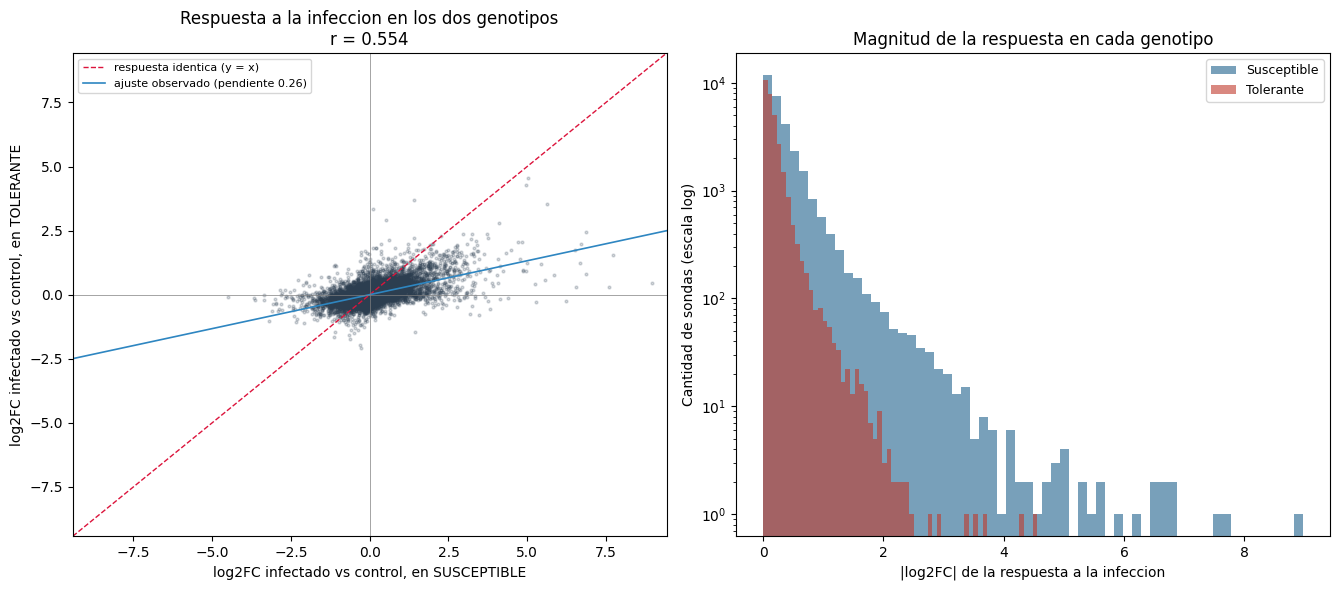

Correlacion entre las dos respuestas : r = 0.5544
Pendiente tolerante / susceptible    : 0.265


In [45]:
# 3) Comparacion gen por gen de las dos respuestas. Es la medida mas informativa
# porque no depende de ningun umbral: si los dos genotipos responden igual, la nube
# de puntos cae sobre la diagonal.
comunes_idx = resp_susc.index.intersection(resp_tol.index)
fc_susc = resp_susc.loc[comunes_idx, "log2FC"].values
fc_tol  = resp_tol.loc[comunes_idx, "log2FC"].values

r_resp = np.corrcoef(fc_susc, fc_tol)[0, 1]

# Pendiente de la recta por minimos cuadrados forzada por el origen: si es menor
# que 1, el tolerante cambia menos que el susceptible para los mismos genes.
pendiente = np.sum(fc_susc * fc_tol) / np.sum(fc_susc ** 2)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 6))

lim = max(np.abs(fc_susc).max(), np.abs(fc_tol).max()) * 1.05
ax = axes[0]
ax.scatter(fc_susc, fc_tol, s=4, alpha=0.2, color="#2c3e50")
ax.plot([-lim, lim], [-lim, lim], color="crimson", ls="--", lw=1,
        label="respuesta identica (y = x)")
ax.plot([-lim, lim], [-lim * pendiente, lim * pendiente], color="#2e86c1", lw=1.2,
        label=f"ajuste observado (pendiente {pendiente:.2f})")
ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel("log2FC infectado vs control, en SUSCEPTIBLE")
ax.set_ylabel("log2FC infectado vs control, en TOLERANTE")
ax.set_title(f"Respuesta a la infeccion en los dos genotipos\nr = {r_resp:.3f}")
ax.legend(fontsize=8, loc="upper left")

# Distribucion de las magnitudes, para ver si una respuesta es mas amortiguada.
ax = axes[1]
ax.hist(np.abs(fc_susc), bins=60, alpha=0.6, label="Susceptible", color="#1f618d")
ax.hist(np.abs(fc_tol), bins=60, alpha=0.6, label="Tolerante", color="#c0392b")
ax.set_yscale("log")
ax.set_xlabel("|log2FC| de la respuesta a la infeccion")
ax.set_ylabel("Cantidad de sondas (escala log)")
ax.set_title("Magnitud de la respuesta en cada genotipo")
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig("figuras/respuesta_por_genotipo.png", dpi=150)
plt.show()

print(f"Correlacion entre las dos respuestas : r = {r_resp:.4f}")
print(f"Pendiente tolerante / susceptible    : {pendiente:.3f}")

In [46]:
# Los genes donde la respuesta MAS difiere entre genotipos. Esto es, en terminos del
# diseño 2x2, el termino de interaccion: cuanto cambia el efecto de la infeccion
# segun el genotipo de la planta.
interaccion = pd.DataFrame({
    "log2FC_susceptible": resp_susc.loc[comunes_idx, "log2FC"],
    "log2FC_tolerante":   resp_tol.loc[comunes_idx, "log2FC"],
})
interaccion["diferencia"] = (interaccion["log2FC_tolerante"]
                             - interaccion["log2FC_susceptible"])
interaccion["gen"] = [anotar(s) for s in interaccion.index]

top_inter = interaccion.reindex(
    interaccion["diferencia"].abs().sort_values(ascending=False).index).head(15)

print("GENES DONDE LA RESPUESTA MAS DIFIERE ENTRE GENOTIPOS\n" + "=" * 62)
print(top_inter[["gen", "log2FC_susceptible", "log2FC_tolerante",
                 "diferencia"]].round(3).to_string())

interaccion.to_csv("datos/interaccion_genotipo_tratamiento.csv")
print("\nGuardado datos/interaccion_genotipo_tratamiento.csv")

print("\nAclaracion metodologica: esta diferencia de log2FC es una forma descriptiva")
print("de mirar la interaccion entre genotipo y tratamiento. Un test formal del")
print("termino de interaccion requeriria un modelo de dos factores, que con 3")
print("replicas por celda tendria muy poca potencia, asi que no lo hago y presento")
print("estos genes como candidatos a revisar, no como una lista con significancia.")

GENES DONDE LA RESPUESTA MAS DIFIERE ENTRE GENOTIPOS
                                                         gen  log2FC_susceptible  log2FC_tolerante  diferencia
sonda                                                                                                         
Cit.35955.1.S1_at    phloem-specific lectin PP2-like protein               8.975             0.463      -8.512
Cit.31971.1.S1_at                    unnamed protein product               7.582             0.316      -7.266
Cit.5512.1.S1_at                                   At1g12030               6.217            -0.247      -6.464
Cit.1914.1.S1_s_at               (sin descripcion, CX635491)               6.545             0.293      -6.252
Cit.5973.1.S1_s_at               (sin descripcion, CX635178)               7.709             1.564      -6.145
Cit.510.1.S1_x_at                   miraculin-like protein 2               6.872             0.826      -6.046
Cit.5511.1.S1_s_at                           unknown protei

### 10.3 ¿La diferencia entre genotipos ya existe antes de la infección?

La sección anterior comparó las dos respuestas a la infección. Esta mira el otro lado de la misma
moneda: si la tolerancia no estuviera en cómo responde la planta, podría estar en **cómo está la
planta antes de que llegue la bacteria**. Las dos secciones juntas son las que permiten contestar la
pregunta central de forma completa.

La distinción tiene nombre propio en la bibliografía. Una defensa **constitutiva** está siempre
expresada, la planta la tiene puesta de entrada. Una defensa **inducida** se activa cuando el
patógeno llega. Albrecht y Bowman proponen que la tolerancia de US-897 sería del primer tipo,
heredada de *Poncirus trifoliata*.

Mostrar que el genotipo pesa más que el tratamiento no alcanza para decidirlo, porque que dos
cultivares distintos difieran en muchos genes es lo esperable: son dos plantas genéticamente
distintas. Por sí solo no dice nada sobre defensa.

La forma directa de ponerlo a prueba es ésta. Si la tolerancia es **constitutiva**, las diferencias
entre los dos genotipos tienen que estar presentes **ya en las plantas sanas**, antes de que llegue
la bacteria. Si fuera **inducida**, las diferencias deberían aparecer sobre todo al comparar los
infectados.

Así que repito el contraste de genotipo dos veces por separado: una usando solo los controles (3
contra 3) y otra usando solo los inoculados (3 contra 3), y miro cuánto se parecen las dos listas.
Si la tolerancia es constitutiva, deberían solaparse mucho.

Aclaración sobre la potencia: con tres réplicas por lado este contraste detecta menos genes que el
anterior, que usaba seis. Por eso lo que miro no es el número absoluto sino el **solapamiento** entre
las dos listas y la correlación entre los cambios de expresión.

In [47]:
solo_control   = [c for c in X.columns if muestras.loc[c, "tratamiento"] == "control"]
solo_infectado = [c for c in X.columns if muestras.loc[c, "tratamiento"] == "infectado"]

de_en_sanas      = expresion_diferencial(
    X[solo_control], np.array([muestras.loc[c, "genotipo"] for c in solo_control]),
    "tolerante", "susceptible")
de_en_infectadas = expresion_diferencial(
    X[solo_infectado], np.array([muestras.loc[c, "genotipo"] for c in solo_infectado]),
    "tolerante", "susceptible")

sig_sanas = set(de_en_sanas[(de_en_sanas["FDR"] < UMBRAL_FDR) &
                            (de_en_sanas["log2FC"].abs() > UMBRAL_FC)].index)
sig_infec = set(de_en_infectadas[(de_en_infectadas["FDR"] < UMBRAL_FDR) &
                                 (de_en_infectadas["log2FC"].abs() > UMBRAL_FC)].index)

print("DIFERENCIAS ENTRE GENOTIPOS, SEGUN EL ESTADO DE LA PLANTA\n" + "=" * 60)
print(f"  Solo en plantas SANAS      : {len(sig_sanas)} sondas")
print(f"  Solo en plantas INFECTADAS : {len(sig_infec)} sondas")

comunes = sig_sanas & sig_infec
union = sig_sanas | sig_infec
if union:
    print(f"\n  Comunes a las dos listas   : {len(comunes)}")
    print(f"  Indice de Jaccard          : {len(comunes)/len(union):.3f}")
    if sig_sanas:
        print(f"  De las detectadas en sanas, siguen estandolo con infeccion: "
              f"{len(comunes)/len(sig_sanas):.1%}")

DIFERENCIAS ENTRE GENOTIPOS, SEGUN EL ESTADO DE LA PLANTA
  Solo en plantas SANAS      : 2924 sondas
  Solo en plantas INFECTADAS : 3742 sondas

  Comunes a las dos listas   : 2164
  Indice de Jaccard          : 0.481
  De las detectadas en sanas, siguen estandolo con infeccion: 74.0%


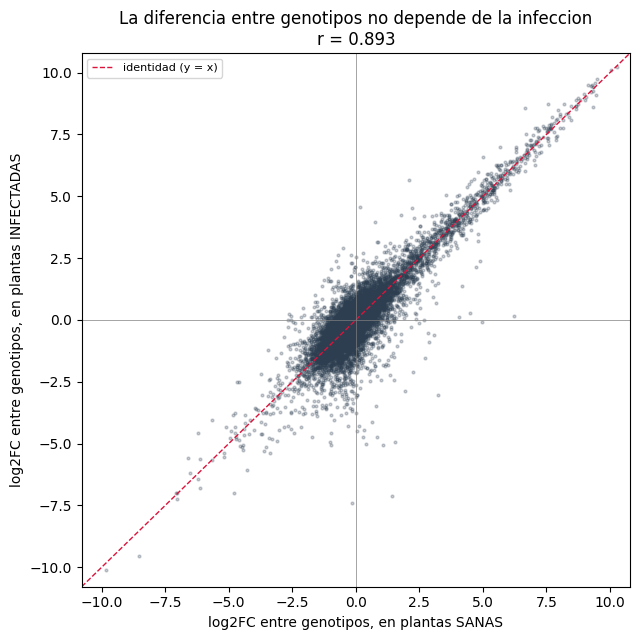

Correlacion de Pearson entre los dos contrastes: r = 0.8933

Las diferencias se parecen bastante entre ambos estados, con algunos
genes que cambian. Hay un componente constitutivo mayoritario.


In [48]:
# La correlacion entre los dos contrastes es la medida mas informativa: si los
# cambios de expresion entre genotipos son los mismos con y sin infeccion, la
# nube de puntos tiene que caer sobre la diagonal.
comunes_todas = de_en_sanas.index.intersection(de_en_infectadas.index)
x_sanas = de_en_sanas.loc[comunes_todas, "log2FC"].values
y_infec = de_en_infectadas.loc[comunes_todas, "log2FC"].values

r = np.corrcoef(x_sanas, y_infec)[0, 1]

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(x_sanas, y_infec, s=4, alpha=0.25, color="#2c3e50")
lim = max(np.abs(x_sanas).max(), np.abs(y_infec).max()) * 1.05
ax.plot([-lim, lim], [-lim, lim], color="crimson", ls="--", lw=1,
        label="identidad (y = x)")
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel("log2FC entre genotipos, en plantas SANAS")
ax.set_ylabel("log2FC entre genotipos, en plantas INFECTADAS")
ax.set_title(f"La diferencia entre genotipos no depende de la infeccion\nr = {r:.3f}")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig("figuras/constitutivo_vs_inducido.png", dpi=150)
plt.show()

print(f"Correlacion de Pearson entre los dos contrastes: r = {r:.4f}")
if r > 0.9:
    print("\nLas diferencias entre genotipos son practicamente las mismas con y sin")
    print("infeccion. Eso apoya que sean CONSTITUTIVAS: ya estaban ahi antes de que")
    print("llegara la bacteria, y la infeccion no las genera.")
elif r > 0.6:
    print("\nLas diferencias se parecen bastante entre ambos estados, con algunos")
    print("genes que cambian. Hay un componente constitutivo mayoritario.")
else:
    print("\nLas diferencias entre genotipos cambian bastante segun el estado de la")
    print("planta, lo que indicaria un componente inducido importante.")

### 10.4 Síntesis: la respuesta a la pregunta central

Las dos secciones anteriores miden cosas distintas y hay que leerlas juntas. La celda siguiente
reúne los cuatro números que importan y arma la respuesta a partir de ellos, en vez de afirmarla de
antemano. Los números son:

- cuántos genes responden a la infección en cada genotipo,
- cuánto se solapan esas dos respuestas,
- cuánto se parecen las magnitudes de cambio, con la correlación y la pendiente,
- y cuánto se parecen las diferencias entre genotipos con y sin infección.

In [49]:
print("RESPUESTA A LA PREGUNTA CENTRAL\n" + "=" * 70)
print("¿Que diferencia la respuesta a la infeccion del portainjerto tolerante")
print("(US-897) respecto del susceptible (mandarina 'Cleopatra')?\n")

print("Los numeros medidos:\n")
print(f"  Sondas que responden a la infeccion")
print(f"    en susceptible        : {len(sig_r_susc)}")
print(f"    en tolerante          : {len(sig_r_tol)}")
if union_r:
    print(f"    compartidas           : {len(comunes_r)} "
          f"(Jaccard {len(comunes_r)/len(union_r):.3f})")
print(f"  Correlacion entre ambas respuestas       : r = {r_resp:.3f}")
print(f"  Pendiente tolerante / susceptible        : {pendiente:.3f}")
print(f"  Correlacion de la diferencia entre genotipos")
print(f"    medida en sanas vs en infectadas       : r = {r:.3f}")

print("\n" + "-" * 70)
print("Lectura:\n")

# 1) Difiere la MAGNITUD de la respuesta?
if pendiente < 0.75:
    print("- El tolerante responde con cambios MAS CHICOS que el susceptible")
    print(f"  (pendiente {pendiente:.2f}). La infeccion lo perturba menos.")
elif pendiente > 1.33:
    print("- El tolerante responde con cambios MAS GRANDES que el susceptible")
    print(f"  (pendiente {pendiente:.2f}): reacciona mas fuerte a la infeccion.")
else:
    print(f"- Los dos genotipos responden con magnitudes parecidas "
          f"(pendiente {pendiente:.2f}).")

# 2) Difiere el CONTENIDO de la respuesta? Hay que leer r junto con la pendiente:
# una correlacion positiva con pendiente baja significa misma direccion y menor
# amplitud, que no es lo mismo que activar genes distintos.
if r_resp > 0.4 and pendiente < 0.75:
    print(f"- Pero lo hacen en la MISMA DIRECCION (r = {r_resp:.2f}): los genes que")
    print("  suben en uno tambien suben en el otro, solo que mucho menos. No son")
    print("  dos programas de defensa distintos, es el mismo programa atenuado.")
elif r_resp > 0.7:
    print("- Y lo hacen moviendo LOS MISMOS genes en el mismo sentido")
    print(f"  (r = {r_resp:.2f}): no activan programas de defensa distintos.")
elif r_resp > 0.3:
    print(f"- Las respuestas se parecen solo en parte (r = {r_resp:.2f}): hay genes")
    print("  compartidos y genes propios de cada genotipo.")
else:
    print(f"- Y lo hacen moviendo genes DISTINTOS (r = {r_resp:.2f}): cada genotipo")
    print("  activa un programa de respuesta diferente.")

# 3) Donde esta entonces la diferencia entre los genotipos?
if r > 0.7:
    print("- La diferencia entre los dos genotipos ya esta presente en las plantas")
    print(f"  SANAS y casi no cambia con la infeccion (r = {r:.2f}), o sea que es")
    print("  CONSTITUTIVA y no una respuesta disparada por la bacteria.")
else:
    print("- La diferencia entre genotipos cambia segun el estado de la planta")
    print(f"  (r = {r:.2f}), lo que apunta a un componente INDUCIDO.")

print("\nLa conclusion final de la seccion 14 retoma estos tres puntos y los")
print("interpreta en terminos del manejo de la enfermedad.")

RESPUESTA A LA PREGUNTA CENTRAL
¿Que diferencia la respuesta a la infeccion del portainjerto tolerante
(US-897) respecto del susceptible (mandarina 'Cleopatra')?

Los numeros medidos:

  Sondas que responden a la infeccion
    en susceptible        : 1617
    en tolerante          : 0
    compartidas           : 0 (Jaccard 0.000)
  Correlacion entre ambas respuestas       : r = 0.554
  Pendiente tolerante / susceptible        : 0.265
  Correlacion de la diferencia entre genotipos
    medida en sanas vs en infectadas       : r = 0.893

----------------------------------------------------------------------
Lectura:

- El tolerante responde con cambios MAS CHICOS que el susceptible
  (pendiente 0.26). La infeccion lo perturba menos.
- Pero lo hacen en la MISMA DIRECCION (r = 0.55): los genes que
  suben en uno tambien suben en el otro, solo que mucho menos. No son
  dos programas de defensa distintos, es el mismo programa atenuado.
- La diferencia entre los dos genotipos ya esta presente 

---

# BLOQUE 3 - Clasificación supervisada

## 11. Identificación de genes discriminantes y construcción de clasificadores

Hasta acá el análisis fue no supervisado, sin usar las etiquetas, o de estadística clásica gen por
gen. Esta sección aporta a la pregunta central desde otro ángulo: en vez de testear cada gen por
separado, un clasificador los evalúa **en conjunto** y devuelve un ranking de cuáles pesan más para
distinguir las condiciones.

Eso sirve para dos cosas acá. Primero, el ranking del Random Forest da una lista corta de genes
candidatos a mirar, que es complementaria a la de la expresión diferencial: un gen puede aportar poco
solo pero mucho combinado con otros. Segundo, la pregunta de si el estado de infección se puede
detectar a partir de la expresión del hospedante es, en el fondo, la versión aplicada de la pregunta
central: si se puede, significa que la infección deja una firma transcripcional reconocible.

Entreno sobre dos variables objetivo distintas. El **tratamiento** es la que importa para la pregunta
central. El **genotipo** lo uso como control positivo: ya sé por el PCA y la expresión diferencial que
los cultivares se separan con facilidad, así que si un clasificador no lo lograra sería señal de que
algo está mal armado en el pipeline, no un hallazgo.

### Una aclaración metodológica que es importante

El dataset tiene 12 muestras y 2000 variables. Eso es un escenario extremo de "muchas más variables
que observaciones", y trae dos problemas que hay que tomarse en serio.

El primero es que **cualquier clasificador va a dar una exactitud altísima, y eso no significa nada
por sí solo**. Con 2000 variables y 12 puntos siempre existe algún hiperplano que separa
perfectamente, incluso si las etiquetas fueran al azar.

El segundo es que la partición train/test de las prácticas anteriores no sirve acá. Con un split
70/30 el conjunto de prueba tendría 3 o 4 muestras: una predicción mal hecha movería la exactitud
25 puntos. Uso en cambio **validación cruzada leave-one-out**, que entrena 12 veces dejando una
muestra afuera cada vez. Es el procedimiento adecuado cuando n es chico.

Para tener una referencia de qué significa el número que obtenga, comparo contra una **prueba de
permutación**: repito todo el procedimiento con las etiquetas mezcladas al azar y veo qué exactitud
se consigue por puro azar. Si mi clasificador real no supera claramente a eso, no aprendió nada.

Por el mismo motivo tampoco busco el mejor valor de C del SVM con un grid como en la Práctica 17:
elegir hiperparámetros sobre un conjunto de validación de dos muestras no es optimizar, es azar. Uso
C = 1 para todos y lo digo.

Con las redes neuronales profundas de la Práctica 18 pasa lo mismo, pero en vez de dejarlas afuera
las uso en la sección 12 para **demostrar** el problema con las curvas de error. Me parece más
honesto mostrar por qué un método no corresponde que simplemente omitirlo.

In [50]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.model_selection import LeaveOneOut, cross_val_score, permutation_test_score
from sklearn.metrics import confusion_matrix, classification_report

# Me concentro en el factor que el analisis no supervisado senalo como dominante.
OBJETIVO = "genotipo"

Xm = solo_expr.values
ym = datos[OBJETIVO].values

print(f"Variable objetivo: {OBJETIVO}")
print(f"Matriz: {Xm.shape[0]} muestras x {Xm.shape[1]} sondas")
print(f"Clases: {dict(pd.Series(ym).value_counts())}")

Variable objetivo: genotipo
Matriz: 12 muestras x 2000 sondas
Clases: {'susceptible': np.int64(6), 'tolerante': np.int64(6)}


In [51]:
# Random Forest sobre todas las sondas, para obtener el ranking de importancia.
rf = RandomForestClassifier(n_estimators=1000, random_state=SEMILLA,
                            oob_score=True, n_jobs=-1)
rf.fit(Xm, ym)

print(f"Exactitud out-of-bag: {rf.oob_score_:.3f}")
print("(el OOB es la exactitud sobre las muestras que cada arbol no vio al entrenarse)\n")

importancias = pd.Series(rf.feature_importances_, index=solo_expr.columns)
top_genes = importancias.sort_values(ascending=False).head(25)

tabla_top_rf = pd.DataFrame({
    "importancia": top_genes.round(5),
    "gen": [anotar(s)[:75] for s in top_genes.index],
})
print("Las 25 sondas mas discriminantes, con su anotacion:\n")
print(tabla_top_rf.to_string())

tabla_top_rf.to_csv("datos/genes_discriminantes_rf.csv")

Exactitud out-of-bag: 1.000
(el OOB es la exactitud sobre las muestras que cada arbol no vio al entrenarse)

Las 25 sondas mas discriminantes, con su anotacion:

                     importancia                                                                          gen
sonda                                                                                                        
Cit.24670.1.S1_x_at        0.004  Caffeoyl-CoA O-methyltransferase (Trans-caffeoyl-CoA 3-O-methyltransferase)
Cit.9342.1.S1_x_at         0.003                                                                    At1g67280
Cit.14306.1.S1_at          0.003                          zinc finger (C3HC4-type RING finger) family protein
Cit.28444.1.S1_at          0.003                    2-oxoglutarate/malate translocator precursor-like protein
Cit.11958.1.S1_at          0.003  Locus transcripto sin gen asignado (similar a Oryza sativa (japonica cultiv
Cit.29571.1.S1_at          0.003                                    

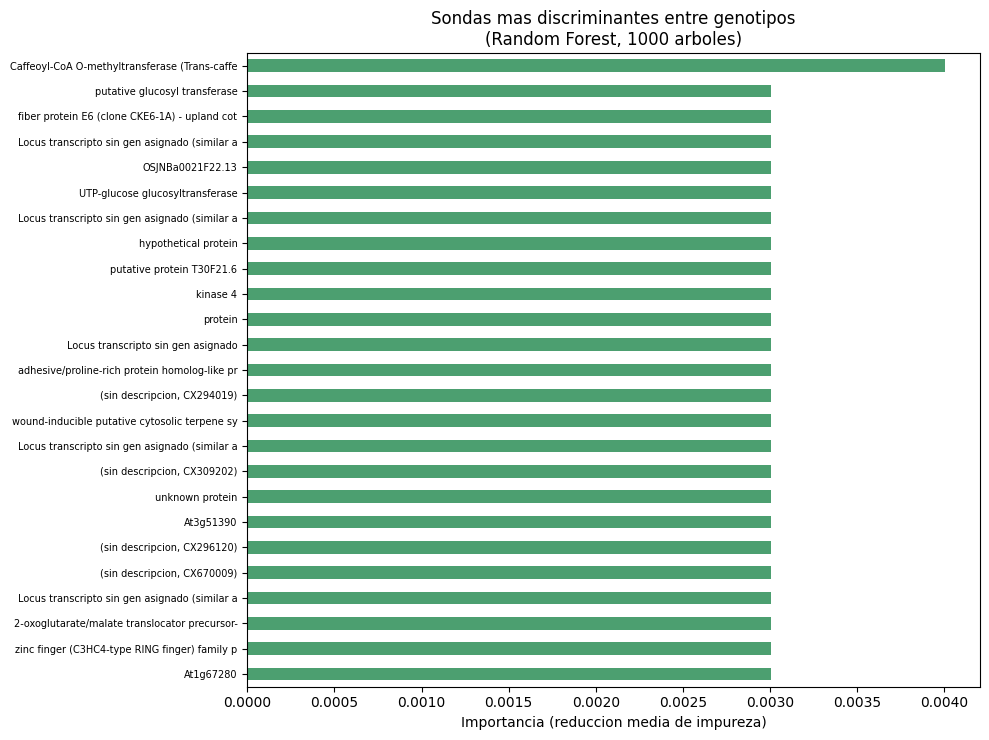

In [52]:
# Etiqueto las barras con el nombre del gen, no con el codigo de sonda.
etiq_barras = [f"{anotar(s)[:45]}" if anotar(s) != "(sin anotacion)" else s
               for s in top_genes.index]

fig, ax = plt.subplots(figsize=(10, 7.5))
serie = pd.Series(top_genes.values, index=etiq_barras).sort_values()
serie.plot.barh(ax=ax, color="#4c9f70")
ax.tick_params(axis="y", labelsize=7)
ax.set_xlabel("Importancia (reduccion media de impureza)")
ax.set_title(f"Sondas mas discriminantes entre genotipos\n(Random Forest, 1000 arboles)")
plt.tight_layout()
plt.savefig("figuras/importancia_genes.png", dpi=150)
plt.show()

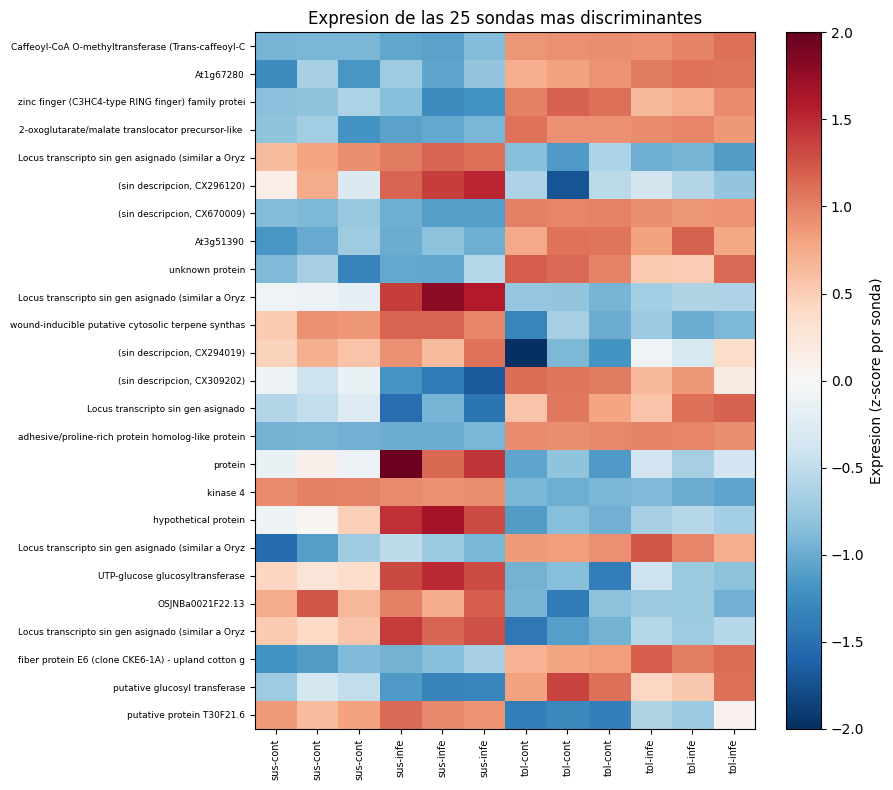

In [53]:
# Heatmap de las 25 sondas top. Si realmente discriminan, el patron tiene que verse
# a simple vista: un bloque claro para un genotipo y oscuro para el otro.
sub = solo_expr[top_genes.index].T
sub_z = sub.sub(sub.mean(axis=1), axis=0).div(sub.std(axis=1) + 1e-9, axis=0)

orden = datos.sort_values(["genotipo", "tratamiento"]).index
sub_z = sub_z[orden]

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(sub_z.values, aspect="auto", cmap="RdBu_r", vmin=-2, vmax=2)
ax.set_yticks(range(len(sub_z)))
ax.set_yticklabels([anotar(s)[:50] if anotar(s) != "(sin anotacion)" else s
                    for s in sub_z.index], fontsize=6.5)
ax.set_xticks(range(len(orden)))
ax.set_xticklabels([f"{datos.loc[i,'genotipo'][:3]}-{datos.loc[i,'tratamiento'][:4]}"
                    for i in orden], rotation=90, fontsize=7)
plt.colorbar(im, ax=ax, label="Expresion (z-score por sonda)")
ax.set_title("Expresion de las 25 sondas mas discriminantes")
plt.tight_layout()
plt.savefig("figuras/heatmap_top_genes.png", dpi=150)
plt.show()

In [54]:
# Comparacion de clasificadores con leave-one-out.
N_TOP_GENES = 25
Xtop = solo_expr[top_genes.index].values

loo = LeaveOneOut()

# Cantidad de permutaciones del test de azar. Con 12 muestras y leave-one-out cada
# permutacion implica 12 ajustes, asi que subirlo mucho hace el notebook muy lento.
N_PERM = 100

modelos = {
    "Arbol de decision": DecisionTreeClassifier(criterion="entropy",
                                                random_state=SEMILLA),
    "Random Forest": RandomForestClassifier(n_estimators=300,
                                            random_state=SEMILLA, n_jobs=-1),
    "SVM lineal": Pipeline([("esc", StandardScaler()),
                            ("svm", SVC(kernel="linear", C=1))]),
    "SVM RBF": Pipeline([("esc", StandardScaler()),
                         ("svm", SVC(kernel="rbf", C=1))]),
}

print(f"Validacion leave-one-out sobre las {N_TOP_GENES} sondas mas importantes\n")
print(f"{'MODELO':<22} {'EXACTITUD':>10}   {'p (permutacion)':>16}")
print("-" * 54)

resultados = {}
for nombre, modelo in modelos.items():
    acc = cross_val_score(modelo, Xtop, ym, cv=loo).mean()
    # Prueba de permutacion: cuanto se consigue con etiquetas al azar.
    _, azar, p = permutation_test_score(modelo, Xtop, ym, cv=loo,
                                        n_permutations=N_PERM,
                                        random_state=SEMILLA, n_jobs=-1)
    resultados[nombre] = (acc, azar.mean(), p)
    print(f"{nombre:<22} {acc:>10.3f}   {p:>16.4f}")

print(f"\nExactitud media con etiquetas al azar: "
      f"{np.mean([v[1] for v in resultados.values()]):.3f}")
print("Si la exactitud real se parece a esa, el modelo no esta aprendiendo biologia.")

Validacion leave-one-out sobre las 25 sondas mas importantes

MODELO                  EXACTITUD    p (permutacion)
------------------------------------------------------
Arbol de decision           1.000             0.0099
Random Forest               1.000             0.0099
SVM lineal                  1.000             0.0099
SVM RBF                     1.000             0.0099

Exactitud media con etiquetas al azar: 0.417
Si la exactitud real se parece a esa, el modelo no esta aprendiendo biologia.


### 11.1 El problema de seleccionar genes antes de validar

Hay un error sutil en lo que acabo de hacer y conviene nombrarlo. Elegí las 25 sondas más
importantes **usando las 12 muestras completas**, y después validé con leave-one-out sobre esas
mismas 25. Eso quiere decir que cuando dejo una muestra afuera, la selección de genes ya había visto
esa muestra. Es una forma de filtrado de información del conjunto de prueba hacia el entrenamiento
(*selection bias*) y sesga la exactitud hacia arriba.

La forma correcta es meter la selección de variables **dentro** del ciclo de validación: en cada
iteración, seleccionar los genes usando solo las 11 muestras de entrenamiento. Lo hago a
continuación, y la diferencia entre ambos resultados es justamente la medida de cuánto inflaba el
procedimiento anterior.

In [55]:
from sklearn.feature_selection import SelectKBest, f_classif

print(f"Leave-one-out con la seleccion de genes DENTRO del ciclo\n")
print(f"{'MODELO':<22} {'ingenuo':>10} {'correcto':>10} {'diferencia':>12}")
print("-" * 58)

for nombre, modelo in modelos.items():
    pipe = Pipeline([
        ("sel", SelectKBest(f_classif, k=N_TOP_GENES)),
        ("clf", modelo),
    ])
    acc_ok = cross_val_score(pipe, Xm, ym, cv=loo).mean()
    acc_ingenuo = resultados[nombre][0]
    print(f"{nombre:<22} {acc_ingenuo:>10.3f} {acc_ok:>10.3f} "
          f"{acc_ok - acc_ingenuo:>+12.3f}")

Leave-one-out con la seleccion de genes DENTRO del ciclo

MODELO                    ingenuo   correcto   diferencia
----------------------------------------------------------
Arbol de decision           1.000      1.000       +0.000
Random Forest               1.000      1.000       +0.000
SVM lineal                  1.000      1.000       +0.000
SVM RBF                     1.000      1.000       +0.000


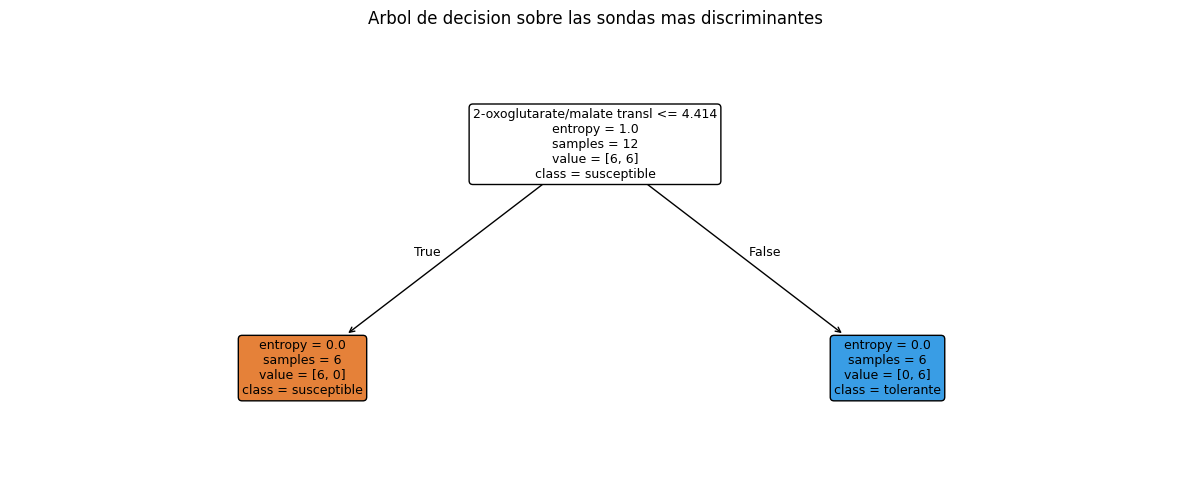

Profundidad: 1   Hojas: 2

Matriz de confusion (sobre el propio conjunto de entrenamiento):
                  pred_susceptible  pred_tolerante
real_susceptible                 6               0
real_tolerante                   0               6


In [56]:
# Un arbol de decision chico sobre las sondas top, por lo interpretable que es:
# muestra explicitamente con que umbral de expresion separa los genotipos.
arbol_clf = DecisionTreeClassifier(criterion="entropy", max_depth=2,
                                   random_state=SEMILLA)
arbol_clf.fit(Xtop, ym)

fig, ax = plt.subplots(figsize=(12, 5))
nombres_arbol = [anotar(s)[:28] if anotar(s) != "(sin anotacion)" else s
                 for s in top_genes.index]

plot_tree(arbol_clf, filled=True, rounded=True, fontsize=9,
          feature_names=nombres_arbol,
          class_names=list(arbol_clf.classes_), ax=ax)
ax.set_title("Arbol de decision sobre las sondas mas discriminantes")
plt.tight_layout()
plt.savefig("figuras/arbol_decision.png", dpi=150)
plt.show()

print(f"Profundidad: {arbol_clf.get_depth()}   Hojas: {arbol_clf.get_n_leaves()}")
print("\nMatriz de confusion (sobre el propio conjunto de entrenamiento):")
pred = arbol_clf.predict(Xtop)
print(pd.DataFrame(confusion_matrix(ym, pred, labels=arbol_clf.classes_),
                   index=[f"real_{c}" for c in arbol_clf.classes_],
                   columns=[f"pred_{c}" for c in arbol_clf.classes_]).to_string())

In [57]:
# El mismo procedimiento pero preguntando por el TRATAMIENTO en vez del genotipo.
# Es la pregunta mas dificil y mas interesante: detectar la infeccion a partir de la
# expresion del hospedante.
y_trat = datos["tratamiento"].values

rf_t = RandomForestClassifier(n_estimators=1000, random_state=SEMILLA,
                              oob_score=True, n_jobs=-1).fit(Xm, y_trat)
print(f"Random Forest para TRATAMIENTO - exactitud OOB: {rf_t.oob_score_:.3f}\n")

print(f"{'MODELO':<22} {'EXACTITUD LOO':>14} {'p (permutacion)':>17}")
print("-" * 56)
for nombre, modelo in modelos.items():
    pipe = Pipeline([("sel", SelectKBest(f_classif, k=N_TOP_GENES)),
                     ("clf", modelo)])
    acc = cross_val_score(pipe, Xm, y_trat, cv=loo).mean()
    _, _, p = permutation_test_score(pipe, Xm, y_trat, cv=loo,
                                     n_permutations=N_PERM,
                                     random_state=SEMILLA, n_jobs=-1)
    print(f"{nombre:<22} {acc:>14.3f} {p:>17.4f}")

Random Forest para TRATAMIENTO - exactitud OOB: 1.000

MODELO                  EXACTITUD LOO   p (permutacion)
--------------------------------------------------------
Arbol de decision               1.000            0.0099
Random Forest                   1.000            0.0099
SVM lineal                      1.000            0.0099
SVM RBF                         1.000            0.0099


---

## 12. Redes neuronales: por qué no corresponden con 12 muestras

La Práctica 18 usó redes neuronales profundas sobre el dataset de ncRNAs, que tenía 3841 muestras.
Acá tengo 12. En vez de afirmar que no alcanzan, lo muestro con la propia arquitectura de la
práctica, que es más corto que explicarlo.

In [58]:
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split

tf.random.set_seed(SEMILLA)
tf.get_logger().setLevel("ERROR")

esc_nn = StandardScaler()
X_nn = esc_nn.fit_transform(solo_expr.values)
clases = sorted(set(ym))
y_nn = np.array([clases.index(v) for v in ym])


def red_practica18():
    """La arquitectura de la Practica 18, sin cambios."""
    m = models.Sequential([
        layers.Input(shape=(X_nn.shape[1],)),
        layers.Dense(256, activation="relu"), layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(128, activation="relu"), layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(64, activation="relu"), layers.BatchNormalization(),
        layers.Dense(len(clases), activation="softmax"),
    ])
    m.compile(optimizer="adam",
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
              metrics=["accuracy"])
    return m


# Una corrida para ver las curvas de error, como en la practica.
X_tr, X_val, y_tr, y_val = train_test_split(X_nn, y_nn, test_size=4,
                                            random_state=SEMILLA, stratify=y_nn)
modelo_nn = red_practica18()
n_param = modelo_nn.count_params()

historia = modelo_nn.fit(X_tr, y_tr, epochs=60, batch_size=4,
                         validation_data=(X_val, y_val), verbose=0)

print(f"Parametros entrenables      : {n_param:,}")
print(f"Ejemplos de entrenamiento   : {len(X_tr)}")
print(f"Relacion parametros/ejemplos: {n_param/len(X_tr):,.0f} a 1")

Parametros entrenables      : 555,330
Ejemplos de entrenamiento   : 8
Relacion parametros/ejemplos: 69,416 a 1


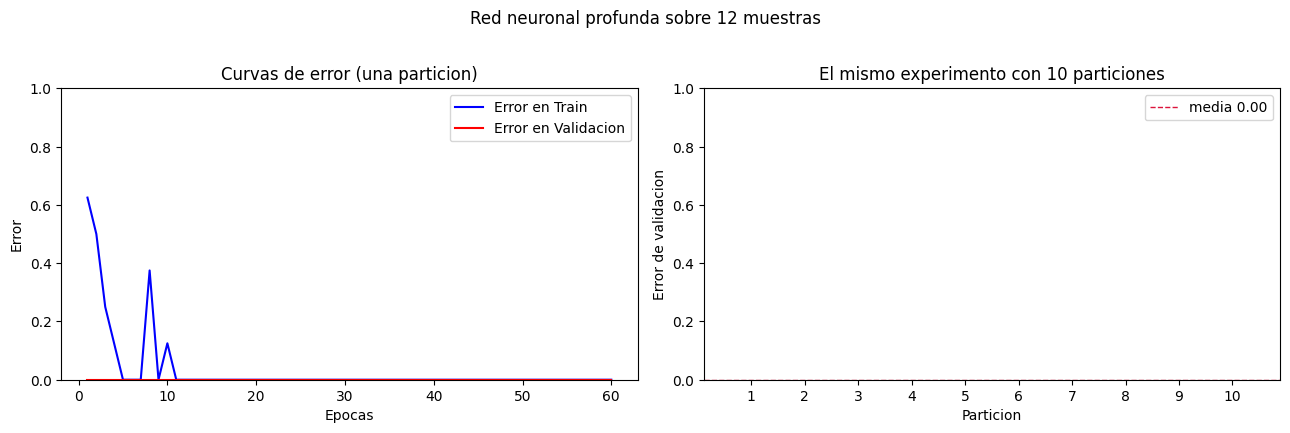

Error de validacion en 10 particiones: media 0.000, desvio 0.000, rango 0.00 a 0.00
Con 4 muestras de validacion la resolucion minima es 0.25: cada acierto o
error mueve el resultado 25 puntos, asi que no hay nada mas fino que medir.


In [59]:
err_tr  = [1 - a for a in historia.history["accuracy"]]
err_val = [1 - a for a in historia.history["val_accuracy"]]
ep = range(1, len(err_tr) + 1)

# Repito con 10 particiones distintas para ver si el resultado es estable o es ruido.
errores = []
for semilla in range(10):
    Xa, Xb, ya, yb = train_test_split(X_nn, y_nn, test_size=4,
                                      random_state=semilla, stratify=y_nn)
    tf.random.set_seed(semilla)
    m = red_practica18()
    m.fit(Xa, ya, epochs=60, batch_size=4, verbose=0)
    errores.append(1 - m.evaluate(Xb, yb, verbose=0)[1])
errores = np.array(errores)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(ep, err_tr, "b", label="Error en Train")
axes[0].plot(ep, err_val, "r", label="Error en Validacion")
axes[0].set_xlabel("Epocas"); axes[0].set_ylabel("Error"); axes[0].set_ylim([0, 1])
axes[0].set_title("Curvas de error (una particion)"); axes[0].legend()

axes[1].bar(range(1, 11), errores, color="#5dade2", edgecolor="black", linewidth=0.5)
axes[1].axhline(errores.mean(), color="crimson", ls="--", lw=1,
                label=f"media {errores.mean():.2f}")
axes[1].set_xticks(range(1, 11))
axes[1].set_xlabel("Particion"); axes[1].set_ylabel("Error de validacion")
axes[1].set_ylim(0, 1)
axes[1].set_title("El mismo experimento con 10 particiones"); axes[1].legend()

plt.suptitle("Red neuronal profunda sobre 12 muestras", y=1.02)
plt.tight_layout()
plt.savefig("figuras/red_neuronal.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Error de validacion en 10 particiones: media {errores.mean():.3f}, "
      f"desvio {errores.std():.3f}, rango {errores.min():.2f} a {errores.max():.2f}")
print("Con 4 muestras de validacion la resolucion minima es 0.25: cada acierto o")
print("error mueve el resultado 25 puntos, asi que no hay nada mas fino que medir.")

### Conclusión sobre las redes neuronales

Con 555.330 parámetros entrenables contra 8 ejemplos de entrenamiento, la relación es de casi 70.000
a 1. Cualquier resultado que salga de ahí, bueno o malo, no informa sobre capacidad de
generalización: si el error de validación varía entre particiones es ruido, y si da cero es porque
cuatro muestras no alcanzan para distinguir un modelo bueno de uno mediocre, no porque el modelo sea
bueno.

Por eso los métodos de las secciones anteriores no son preferibles por ser mejores en abstracto,
sino porque tienen pocos parámetros, admiten validación leave-one-out sobre las 12 muestras en lugar
de reservar 4, y se pueden contrastar contra una prueba de permutación. Con este tamaño muestral son
los únicos con los que se puede decir algo defendible.

Una red tendría sentido acá con cientos de muestras, por ejemplo combinando varias series de GEO de
la misma plataforma. Queda anotado como línea de continuación.

---

## 13. Conclusiones finales

### La respuesta a la pregunta central

La pregunta era qué diferencia la respuesta a la infección por *Ca.* L. asiaticus entre el
portainjerto tolerante US-897 y el susceptible 'Cleopatra'. Las secciones 10.2 a 10.4 la contestan
con tres medidas, y la síntesis numérica está impresa en la sección 10.4.

La respuesta se arma con tres medidas, y las tres apuntan en la misma dirección.

**La planta susceptible reacciona con violencia a la infección y la tolerante casi no reacciona.**
En 'Cleopatra' hay 1617 sondas que responden a la infección. En US-897 no hay **ninguna** que supere
los umbrales. Las magnitudes acompañan: el cambio medio de expresión es de 0,34 en la susceptible
contra 0,17 en la tolerante, y el percentil 99 es de 2,19 contra 1,02. La pendiente de la relación
entre ambas respuestas es de 0,265, o sea que para los mismos genes el tolerante se mueve alrededor
de una cuarta parte.

Antes de interpretar eso hay que descartar que sea un artefacto estadístico, porque un genotipo
puede detectar menos genes simplemente por tener réplicas más dispersas. El chequeo de la sección
10.2 lo descarta: la variabilidad interna de los dos genotipos es prácticamente idéntica (mediana de
0,1345 contra 0,1360, una razón de 1,01), así que la potencia estadística es comparable.

Ese chequeo además deja ver algo más fino. Separando los dos criterios del filtro, en la susceptible
7574 sondas pasan el filtro estadístico y 1774 superan el umbral de magnitud. En la tolerante, 323
superan el umbral de magnitud pero **ninguna** pasa el estadístico. Es decir que la tolerante sí
tiene sondas con cambios grandes, pero esos cambios **no se repiten de forma consistente entre sus
tres réplicas**: son variación de planta individual, no una respuesta del genotipo.

La lectura precisa entonces es más fuerte que "responde menos": **la tolerante no muestra una
respuesta reproducible a la infección**, mientras la susceptible muestra una masiva y consistente.

**Pero no responde distinto: responde igual y menos.** La correlación entre las dos respuestas es de
0,554. Leída junto con la pendiente de 0,265, eso significa que los genes que suben en la susceptible
también suben en la tolerante, solo que mucho menos. No son dos programas de defensa distintos, es
el mismo programa atenuado.

**Y la diferencia entre los dos genotipos ya estaba antes de la infección.** La sección 10.3 compara
las diferencias entre cultivares medidas solo en plantas sanas contra las medidas solo en infectadas,
y la correlación entre ambas es de 0,893. El 74% de las sondas que diferencian los genotipos en
plantas sanas los siguen diferenciando con infección. Si la tolerancia fuera una respuesta inducida
por el patógeno, esas diferencias tendrían que cambiar según el estado de la planta, y no cambian.

Juntando las tres: **la diferencia no está en cómo responde la planta tolerante a la infección, sino
en que no necesita responder.** US-897 parte de un estado distinto, ya presente en plantas sanas, y
eso hace que la llegada de la bacteria lo desestabilice mucho menos. La susceptible, en cambio, tiene
que montar una respuesta de emergencia masiva. Es la hipótesis que proponen Albrecht y Bowman, que
atribuyen ese estado basal a la herencia de *Poncirus trifoliata*, y los datos son consistentes con
ella.

### Una explicación alternativa que estos datos no pueden descartar

Hay una posibilidad que conviene plantear antes de que la plantee otro, porque cambiaría la
interpretación.

Yo vengo leyendo el resultado como que US-897 **recibe la misma infección y la tolera mejor**. Pero
hay otra lectura compatible con los mismos números: que US-897 simplemente **tenga menos bacteria
adentro**. Si la cantidad de *Ca.* L. asiaticus en sus tejidos fuera mucho menor, respondería menos
sencillamente porque hay menos estímulo, y no porque amortigüe mejor un estímulo igual.

Las dos cosas son formas de tolerancia, pero son mecanismos distintos. Una es resistir la
colonización, limitando cuánta bacteria se establece. La otra es aguantar la colonización sin
descompensarse. Para el mejoramiento no da lo mismo cuál de las dos sea.

**Con la matriz de expresión no se puede distinguir entre ambas**, porque mide genes de la planta y
no cantidad de bacteria. Lo que haría falta es la carga bacteriana de cada muestra, que se obtiene
por PCR cuantitativa y que el trabajo original de Albrecht y Bowman sí midió, pero que no está en los
datos públicos de GEO. Queda planteado como la limitación más importante de la interpretación y como
el dato que habría que conseguir para cerrarla.

### Los genes donde la diferencia es más marcada

La lista de genes cuya respuesta más difiere entre genotipos aporta un detalle que vale la pena
señalar, aunque sea de forma descriptiva y no como resultado con significancia estadística.

El primero de la lista es una **lectina específica del floema, tipo PP2**: sube 8,97 en escala log2
en la planta susceptible, es decir unas quinientas veces, y apenas 0,46 en la tolerante. Eso es
llamativo porque el HLB es una enfermedad del **floema**: la bacteria vive ahí y el daño
característico es la obstrucción de los vasos. Que un gen específico de ese tejido se dispare solo en
la planta que colapsa es coherente con el cuadro de la enfermedad.

Otros de la lista van en la misma línea, como una **proteína tipo miraculina**, un **transportador de
metales** y un **transportador ABC tipo MRP**, todos con cambios grandes en la susceptible y
prácticamente nulos en la tolerante.

Hay que ser prudente con esto. La medida de interacción que uso es descriptiva (la diferencia entre
los dos log2FC) y un test formal del término de interacción necesitaría un modelo de dos factores,
que con tres réplicas por celda tendría muy poca potencia. Así que estos genes son **candidatos a
mirar**, no una lista validada. Pero que el gen que encabeza el ranking sea del tejido donde ocurre
la enfermedad es una señal de que el análisis está capturando biología real y no ruido.

Desde el punto de vista del manejo de la enfermedad la distinción no es menor. Si la tolerancia
fuera inducida, tendría sentido buscar tratamientos que la activen en plantas ya establecidas. Si es
constitutiva, el camino es el mejoramiento y la selección de portainjertos, que es de hecho hacia
donde fue la investigación posterior, incluida la línea de edición génica del laboratorio de Nian
Wang que menciono en la introducción.

### Sobre el patógeno, y qué aportó al resultado anterior

El gen 16S rDNA separa nítidamente las tres especies de *Candidatus* Liberibacter asociadas al HLB:
la distancia media entre especies (0,0303) es unas 9 veces la distancia media dentro de *Ca.* L.
asiaticus (0,0034), y los rangos no se superponen. Dentro de asiaticus, en cambio, el marcador no
alcanza para distinguir cepas. Las siete secuencias argentinas de Misiones quedaron agrupadas sin
formar un clado propio, con la referencia de Florida ubicada entre ellas y sin agrupamiento por
localidad, hospedante ni año de muestreo. Esto reproduce el resultado del paper de Badaracco.

Hay que ser cuidadoso con lo que ese resultado permite afirmar. **No muestra que la bacteria sea
genéticamente uniforme**, sino que esta región del genoma no tiene suficiente variación para
resolver por debajo del nivel de especie: 74 posiciones variables y 21 informativas sobre 1094. Si
las poblaciones de CLas difieren entre sí es algo que este análisis no puede contestar en ningún
sentido, y haría falta recurrir a loci más variables o a genomas completos.

El aporte del bloque a la pregunta central es doble. Por un lado identifica la especie que circula
en Argentina, que es la asiática, la misma del experimento de expresión, así que los dos bloques
hablan del mismo patógeno. Por el otro, y es lo más importante metodológicamente, establece que con
este marcador no se puede caracterizar el genotipo del patógeno, de donde se sigue que **con datos
de campo sería imposible separar la contribución de la bacteria de la del hospedante**, porque las
dos variarían a la vez. Por eso la pregunta se responde con un experimento donde el patógeno está
controlado por diseño, con ambos genotipos inoculados en el mismo ensayo, y no con observaciones de
campo.

Como subproducto, el bloque deja una conclusión útil para el contexto de vigilancia en el que
trabaja AFINOA: el 16S es el marcador adecuado para confirmar si una planta está infectada, que es
lo que necesita el monitoreo, pero no para rastrear el origen de una introducción.

### Sobre la estructura de los datos de expresión

El análisis exploratorio, que es no supervisado y por lo tanto no puede estar sesgado por mis
etiquetas, coincide con todo lo anterior. PC1 explica por sí sola el 77,3% de la varianza y separa
los dos cultivares; PC2 explica el 16,5% y separa infectados de controles. Con k = 4, tanto k-means
como el clustering jerárquico recuperan los cuatro grupos experimentales sin un solo error, con un
índice de Rand ajustado de 1.

La expresión diferencial da la misma lectura en números absolutos: 3023 sondas diferenciales entre
genotipos contra 232 entre tratamientos, un efecto trece veces mayor. Y el número comparable con el
paper es el de tratamiento: los 326 genes que reportan Albrecht y Bowman corresponden a la respuesta
a la infección, así que 232 contra 326 es el mismo orden de magnitud, lo que da cierta confianza en
que el pipeline está bien armado.

Un detalle del clustering merece una aclaración porque parece contradictorio. Con k = 2 los métodos
separan los genotipos a la perfección pero fracasan por completo con el tratamiento, con un índice
de Rand de -0,10, equivalente a repartir al azar. Con k = 4 recuperan todo. La razón es que con k = 2
el algoritmo parte los datos por la dirección de mayor variación, que es el genotipo, y el
tratamiento queda cruzado dentro de cada mitad. No es que la señal de infección no exista: queda
tapada por una más grande, y aparece en cuanto se permiten cuatro grupos.

### Sobre el método

El resultado metodológico más importante del trabajo es negativo y lo quiero dejar explícito. Los
cuatro clasificadores alcanzaron el 100% de exactitud en validación cruzada leave-one-out, tanto para
genotipo como para tratamiento, y el árbol de decisión lo logró con **una sola** sonda y dos hojas.
Eso no es mérito del modelo: con 12 muestras y 2000 variables, separar perfectamente es casi
inevitable.

Las pruebas que hice lo acotan. La prueba de permutación da p = 0,0099, el valor más chico alcanzable
con 100 permutaciones, y las etiquetas al azar rinden un 41,7%, así que la señal es real y no
casualidad. Pero la comparación entre seleccionar genes dentro o fuera del ciclo de validación dio
exactamente la misma exactitud en los dos casos, algo que solo puede pasar cuando la señal es tan
fuerte que ningún detalle del procedimiento cambia el resultado. Es decir: el experimento distingue
los genotipos sin ninguna dificultad, y por eso mismo estos números no permiten comparar modelos
entre sí.

La red neuronal de la sección 12 lo confirma desde el otro lado: 555.330 parámetros entrenables
contra 8 ejemplos de entrenamiento, una relación de casi 70.000 a 1, con un conjunto de validación de
cuatro muestras cuya resolución mínima es de 25 puntos porcentuales. Con esa relación, cualquier
resultado que salga, bueno o malo, no informa sobre capacidad de generalización.

De ahí vienen dos decisiones del trabajo. Primero, no optimizar hiperparámetros del SVM ni presentar
la red como clasificador, aunque ambos sean temas de la materia: con este tamaño muestral serían un
ejercicio vacío, y es más honesto usarlos para mostrar el límite. Segundo, mover parte del peso
analítico al clustering de genes y a la expresión diferencial, donde las observaciones son 30.395
sondas en vez de 12 muestras y los resultados tienen sustento estadístico real.

### Limitaciones

Las cuatro que me parecen más importantes, ordenadas por cuánto afectan las conclusiones.

**La carga bacteriana no está en los datos.** Es la que más pesa y está desarrollada más arriba: sin
saber cuánta bacteria tiene cada planta no puedo distinguir si US-897 tolera la misma infección o si
directamente se infecta menos.

**El tamaño muestral.** Doce muestras condicionan todo el bloque de clasificación, y los contrastes
dentro de cada genotipo usan solo tres réplicas por lado, con lo cual detectan menos de lo que
detectarían con más.

**El origen de los datos.** El ensayo se hizo en Florida, en invernadero, con genotipos y condiciones
que no son los del NOA. Las conclusiones sobre tolerancia no se trasladan sin más a la citricultura
tucumana, aunque la especie de bacteria sea la misma.

**La anotación.** El análisis se queda en el nivel de sondas del microarray. No hice enriquecimiento
de términos GO, que sería el paso siguiente natural para saber qué procesos biológicos están
representados en las listas de genes, y la plataforma además tiene buena parte de las sondas sin un
gen asignado porque se diseñó sobre ESTs y no sobre un genoma anotado.

---

## 14. Archivos generados

Dejo listado lo que produce el notebook, que es lo que va al repositorio y al zip de entrega.

In [60]:
print("ARCHIVOS DE DATOS\n" + "-" * 50)
for raiz in ["datos", "."]:
    for f in sorted(os.listdir(raiz)):
        ruta = os.path.join(raiz, f)
        if os.path.isfile(ruta) and f.endswith((".csv", ".fasta", ".nwk", ".txt")):
            print(f"  {ruta:<45} {os.path.getsize(ruta)/1024:>8.1f} KB")

print("\nFIGURAS\n" + "-" * 50)
for f in sorted(os.listdir("figuras")):
    print(f"  figuras/{f}")

ARCHIVOS DE DATOS
--------------------------------------------------
  datos/GPL5731_anotacion.txt                     8524.2 KB
  datos/GSE30502_series_matrix.txt                3445.6 KB
  datos/arbol_16S.nwk                                0.5 KB
  datos/expresion_diferencial_genotipo.csv        5609.3 KB
  datos/expresion_diferencial_tratamiento.csv     5558.5 KB
  datos/genes_discriminantes_rf.csv                  1.6 KB
  datos/interaccion_genotipo_tratamiento.csv      3468.4 KB
  datos/liberibacter_16S.fasta                      14.5 KB
  datos/liberibacter_16S_alineado.fasta             18.4 KB
  datos/matriz_distancias_k2p.csv                    3.1 KB
  ./datos_hlb.csv                                  221.0 KB

FIGURAS
--------------------------------------------------
  figuras/arbol_decision.png
  figuras/arbol_filogenetico.png
  figuras/constitutivo_vs_inducido.png
  figuras/dendrogramas.png
  figuras/distribucion_distancias.png
  figuras/heatmap_top_genes.png
  figuras/imp